`[БРД090] Расчет подачи метанола в газопроводы в зависимости от температуры промерзания грунта`

Разрабатываемое решение представляет собой гибридную систему расчета потребности в метаноле для предотвращения гидратообразования, объединяющую методы машинного обучения и существующие инженерные алгоритмы.

При реализации кейса был создан веб-интерфейс итогового решения, который позволяет регулировать подачу метанола по участкам трубопроводов. При этом работа с данными по методологии CRISP-DM проведена не была (в предыдущем коде просто создавались ML-модели на всех данных без их валидации).

Поскольку именно от ML-моделей зависят будущие эффекты кейса, в ходе консультаций с разработчиками из Практики бизнес и продвинутой аналитики было принято решение перезагрузить работу над кейсом и начать с разработки ML-моделей с нуля (при их поддержке).

На данный момент по кейсу имеется легаси-код streamlit-приложения, который отправлялся на валидацию 2 раза. Поскольку он не содержит подходов по разработке моделей машинного обучения, далее он использоваться не будет. Этот код (в случае успешного прохождения валидации и бизнес-экспертизы) будет приложен к этапу операционализации воронки (на его основе будет разработано итоговое веб-приложение, включающее хэширование моделей, авторизацию и сбор метрик и логов).

Далее речь пойдет непосредственно о разработке кейса.

---------------

Состав ML-моделей определяется различиями в бизнес-задачах, уровне детализации исходных данных и назначении отдельных этапов инженерного расчета. Кейс БРД090 состоит из следующих компонент.

1. `Сценарная модель прогнозирования потребности в метаноле`

Предназначена для определения итогового расхода метанола по источникам подачи при заданных параметрах технологического режима. Модель позволяет аппроксимировать результаты комплексного инженерного расчета, включая правила распределения потребности между ДНС. Ее результат непосредственно используется для формирования итоговой рекомендации оператору.

2. `Точечная модель классификации`

Предназначена для определения необходимости подачи метанола в расчетных точках трубопровода. Результаты могут использоваться для выявления потенциально критичных участков и детализации сценарного расчета. Корректность локальной интерпретации модели определяется семантикой исходной целевой переменной.

3. `Точечная модель регрессии`

Предназначена для количественной оценки локальной потребности в метаноле. Позволяет детализировать расчет по отдельным точкам и участкам трубопровода, а также исследовать вклад локальных технологических параметров в формирование итоговой потребности.

4. `Суррогатная-модель классификации для Северо-Янгтинского месторождения`

Предназначена для ускоренного воспроизведения результатов термодинамических расчетов Multiflash в части определения наличия гидратной фазы. Используется как вычислительный компонент гибридной инженерной системы и позволяет потенциально сократить количество обращений к ресурсоемкому расчетному инструменту.

5. `Суррогатная-модель регрессии для Северо-Янгтинского месторождения`

Предназначена для аппроксимации расчетного соотношения метанола и воды, получаемого в Multiflash. Результаты используются на последующих этапах инженерного расчета потребности в метаноле.

Таким образом, разработка нескольких моделей обусловлена не дублированием функциональности, а необходимостью решения различных подзадач: прогнозирования итоговой потребности, локализации критичных участков и ускорения термодинамических расчетов.

Применение машинного обучения позволяет ускорить выполнение расчетов и автоматизировать получение рекомендаций на основе существующих инженерных моделей. При этом качество ML-компонентов оценивается относительно результатов соответствующих инженерных расчетов и не подменяет собой независимую проверку физической корректности исходных расчетных методик.

Данный ноутбук посвящен разработке **`суррогатных моделей регрессии и классификации (модели 4 и 5)`**.

`Содержание ноутбука`

`Формирование окружения для работы`

Первоначально необходимо подготовить окружение для работы с данными и их моделирования. Чтобы не возникало конфликтов виртуальной среды Python, зафиксируем используемые в ходе исследования версии основных библиотек и фреймворков, которые будут использоваться далее. А также пропишем последовательность команд для формирования среды.

Работа справедлива для версии `Python3.11+` (выполнялась на платформе N1).

Первоначально установим необходимые библиотеки при помощи пакетного менеджера `pip` в виртуальное окружение. Также зафиксируем версии библиотек далее.

Данные библиотеки можно установить, поместив их вместе с версиями в файл `requirements.txt`. И выполнимв команду ниже.

```
!pip install --upgrade --force-reinstall -r requirements.txt
```

In [1]:
# !pip install --upgrade --force-reinstall -r requirements.txt

Средствами Python импортируем необходимые для работы библиотеки. В силу традиции, присвоим некоторым модулям псевдонимы (например, pd для pandas и т.д.). Роль импортируемых библиотек и фреймворков представлена в таблице. 

| Наименование библиотеки | Описание                                                                             |
| ----------------------- | ------------------------------------------------------------------------------------ |
| matplotlib              | Библиотека для визуализации данных                                                   |
| pandas                  | Библиотека для работы таблицами и плоскими данными                                   |
| numpy                   | Библиотека для работы с массивами и матрицами                                        |
| scikit-learn            | Библиотека для построения классических моделей машинного обучения и работы с данными |
| scipy                   | Библиотека для работы со статистическими объектами                                   |
| missingno               | Библиотека для визуализации пропусков в данных                                       |
| seaborn                 | Библиотека для визуализации данных                                                   |
| plotly                  | Библиотека для визуализации данных                                                   |
| category_encoders       | Библиотека для кодирования категориальных признаков в вещественные значения          |
| typing                  | Библиотека для типизации парамеров функций и переменных                              |
| warnings                | Библиотека для корректировки выводов предупреждений                                  |

In [2]:
import pandas as pd
import numpy as np
import typing as t

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import warnings
warnings.filterwarnings('ignore')

Для воспроизводимости результатов исследования зафиксируем основание генератора случайных чисел, который используется для деления выборки на обучение и тест, а также при обучении моделей.

In [5]:
seed = 5
np.random.seed(seed)

# 1. Предварительная обработка данных

| Название признака | Описание (семантика) | Тип данных |
|---|---|---|
| `calculation_temperature_C` | Температура, при которой выполнялся расчет Multiflash, °C | Вещественный |
| `calculation_pressure_bara` | Абсолютное давление, при котором выполнялся расчет Multiflash, bara | Вещественный |

| Название признака | Описание (семантика) | Тип данных |
|---|---|---|
| `mf_ratio_kg_per_kg_water` | Расчетное отношение массового расхода метанола к массовому расходу воды | Вещественный |
| `mf_hydrate_present` | Признак наличия гидратной фазы по результатам расчета Multiflash | Бинарный |
| `mf_meoh_wt_pct_aqueous` | Массовая доля метанола в водной фазе по результатам Multiflash, % | Вещественный |
| `mf_hydrate_structure` | Тип структуры образовавшихся гидратов | Категориальный |
| `mf_ice_present` | Признак наличия ледяной фазы | Бинарный |

# 1.1. Загрузка исходных данных

Благодаря сформированному виртуальному окружению можно приступить к загрузке данных.

Данные представлены в формате .csv: это значит, что нам необходимо воспользоваться средствами библиотеки pandas, чтобы прочитать, распарсить и проанализировать полученный объект.
Воспользуемся методом ```pd.read_csv()``` для того, чтобы прочитать файл с данными и представить его в памяти.

Данный метод принимает на вход:
1. путь до файла, который необходимо прочитать;
2. разделитель (символ, который отделяет разные записи друг от друга);
3. кодировка (кодировка символов в файле);
4. и т.д.
Прочитаем файл при помощи метода и результат положим в переменную df, с которой будем в дальнейшем работать.

В данном случае параметры разделителя и кодировки передавать нет необходимости, так как для данного файла они совпадают с параметрами по умолчанию: запятая и UTF-8 соответственно.
Метод вернет объект датафрейма (абстракция над табличными данными и табличными представлениями, предоставляющая возможность реализовывать логику по работе с плоскими данными), который необходимо отобразить после прочтения файла.
Также в качестве параметров укажем наименования признаков, которые необходимо представить в формате даты. Для этого в параметр parse_dates передадим список наименований колонок с датами, а также поставим флаг ```dayfirst=True``` для корректного представления.
Сам датасет представляет из себя набор объектов, каждый из которых является комбинацией технологических параметров работы добывающего насосного оборудования, а также параметров работы данного оборудования. Данные параметры составляют матрицу объект-признак.

In [6]:
df = pd.read_csv('./data/Severo_Yangtinskoye_All_Points__MF_Nodes.csv')
df

,node_id,temperature_bin,pressure_bin,temperature_step_C,pressure_step_kg_cm2g,source_point_count,calculation_temperature_C,calculation_pressure_bara,calculation_pressure_barg,calculation_pressure_mpag,...,mf_status,mf_ratio_kg_per_kg_water,mf_meoh_wt_pct_aqueous,mf_hydrate_present,mf_hydrate_structure,mf_ice_present,mf_iterations,mf_calculation_seconds,mf_error,mf_calculated_at
0,1,-124,175,0.05,0.02,3,-6.213607,4.452868,3.439618,0.343962,...,complete,0.0,NaN,0,NaN,NaN,NaN,6.060333,NaN,2026-07-23T14:55:51
1,2,-124,176,0.05,0.02,2,-6.209918,4.464722,3.451472,0.345147,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.227852,NaN,2026-07-23T14:56:00
2,3,-124,177,0.05,0.02,1,-6.202629,4.480302,3.467052,0.346705,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.280766,NaN,2026-07-23T14:56:21
3,4,-124,178,0.05,0.02,3,-6.204083,4.513239,3.499989,0.349999,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.233318,NaN,2026-07-23T14:56:13
4,5,-124,179,0.05,0.02,1,-6.175050,4.523761,3.510511,0.351051,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.262192,NaN,2026-07-23T14:59:16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6457,6458,49,373,0.05,0.02,1,2.443710,8.336855,7.323605,0.732360,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.244152,NaN,2026-07-24T13:02:32
6458,6459,49,374,0.05,0.02,1,2.439843,8.353231,7.339981,0.733998,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.260494,NaN,2026-07-24T13:02:27
6459,6460,52,377,0.05,0.02,1,2.612849,8.408640,7.395390,0.739539,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.263126,NaN,2026-07-24T13:02:36
6460,6461,56,377,0.05,0.02,1,2.790351,8.411007,7.397757,0.739776,...,complete,0.0,NaN,0,NaN,NaN,NaN,4.245271,NaN,2026-07-24T13:02:40


In [7]:
feature_columns = [
    "calculation_temperature_C",
    "calculation_pressure_bara",
]

target_columns = [
    "mf_ratio_kg_per_kg_water", # регрессия
    "mf_hydrate_present", # классификаци
]

In [8]:
df = df[feature_columns + target_columns]
df

,calculation_temperature_C,calculation_pressure_bara,mf_ratio_kg_per_kg_water,mf_hydrate_present
0,-6.213607,4.452868,0.0,0
1,-6.209918,4.464722,0.0,0
2,-6.202629,4.480302,0.0,0
3,-6.204083,4.513239,0.0,0
4,-6.175050,4.523761,0.0,0
...,...,...,...,...
6457,2.443710,8.336855,0.0,0
6458,2.439843,8.353231,0.0,0
6459,2.612849,8.408640,0.0,0
6460,2.790351,8.411007,0.0,0


## 1.2. Профилирование данных

### 1.2.1. Общее профилирование

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6462 entries, 0 to 6461
Data columns (total 4 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   calculation_temperature_C  6462 non-null   float64
 1   calculation_pressure_bara  6462 non-null   float64
 2   mf_ratio_kg_per_kg_water   6462 non-null   float64
 3   mf_hydrate_present         6462 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 202.1 KB


In [10]:
df.describe()

,calculation_temperature_C,calculation_pressure_bara,mf_ratio_kg_per_kg_water,mf_hydrate_present
count,6462.000000,6462.000000,6462.000000,6462.000000
mean,-2.746723,6.493728,0.093177,0.807026
std,2.289475,0.860454,0.124681,0.394664
min,-6.214419,4.446157,0.000000,0.000000
25%,-4.934638,5.877731,0.020723,1.000000
50%,-2.995855,6.511111,0.093045,1.000000
75%,-0.969847,7.141099,0.149988,1.000000
max,2.888214,8.411007,8.350380,1.000000


<Axes: >

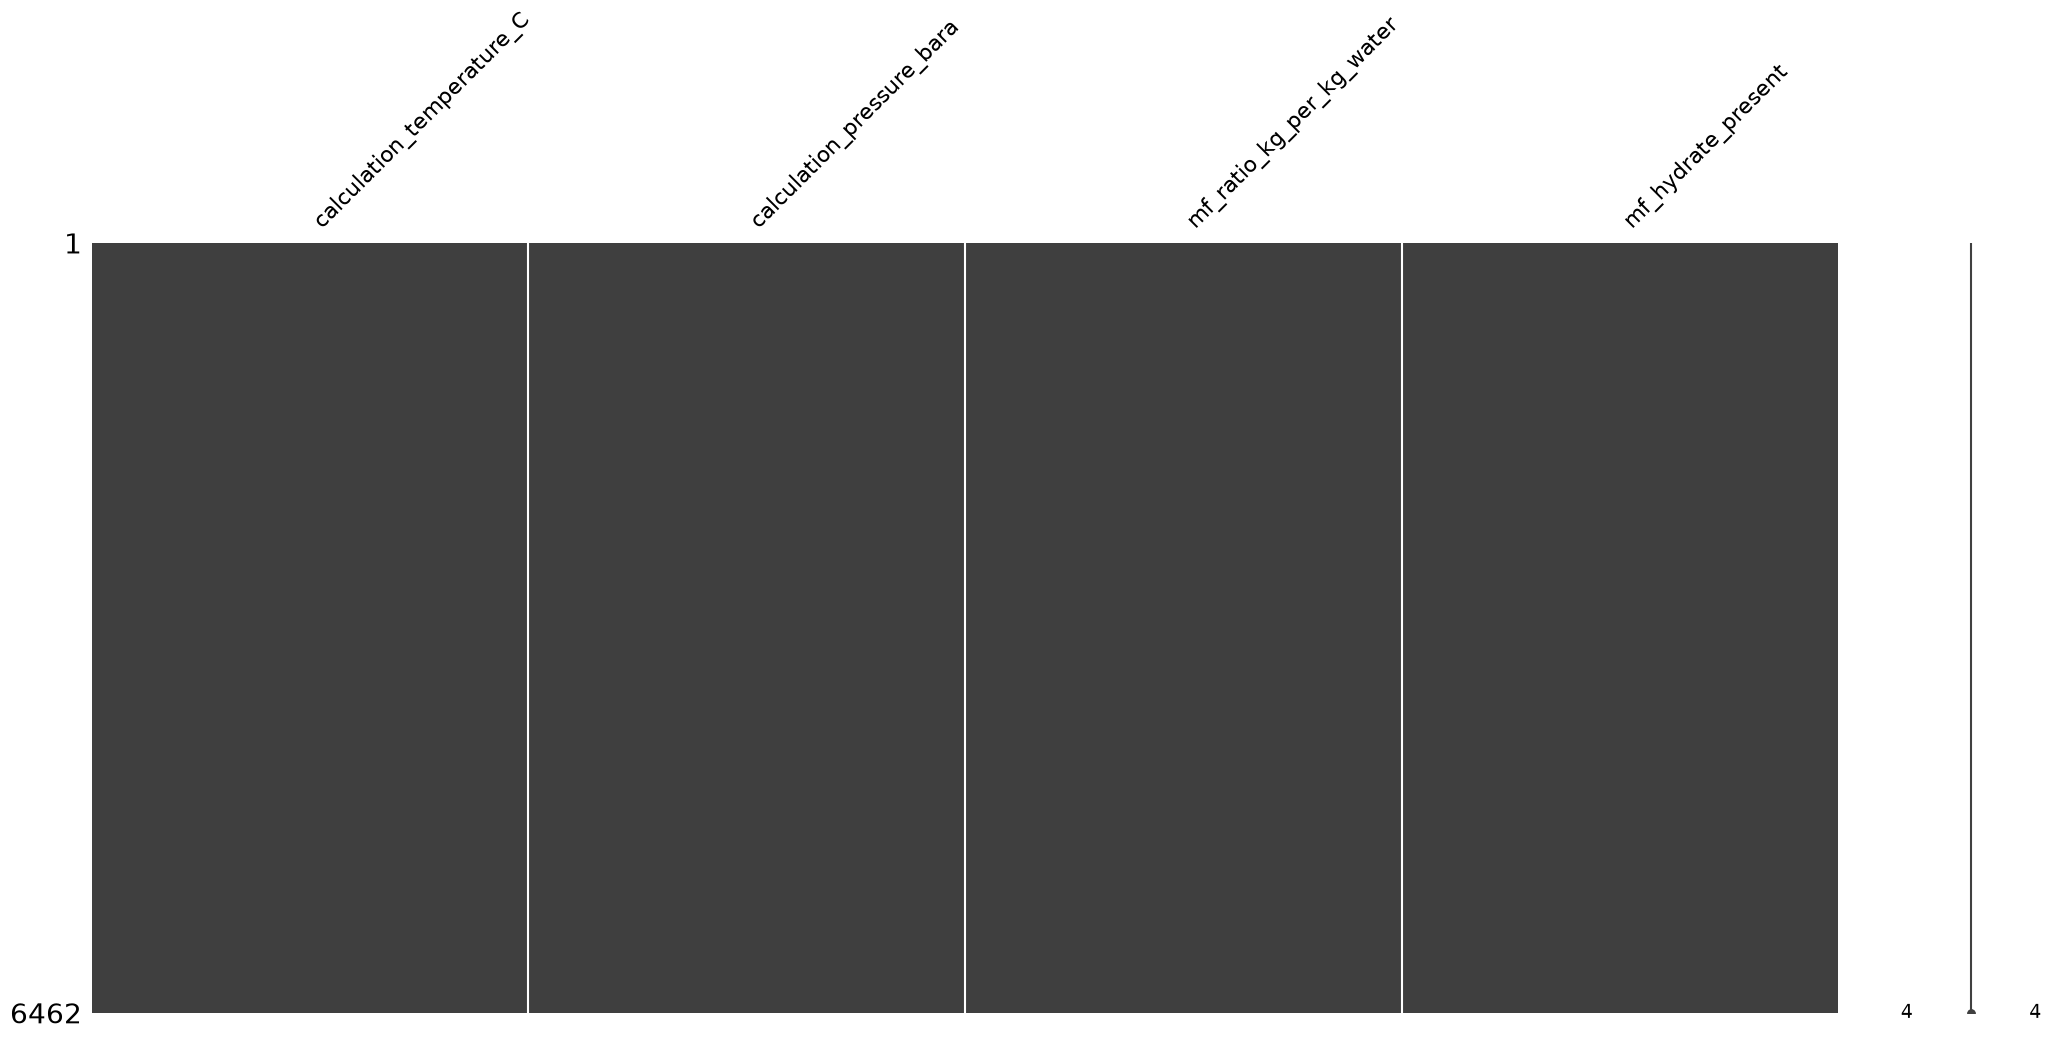

In [11]:
import missingno as msgn


msgn.matrix(df)

In [12]:
df.isna().sum()

calculation_temperature_C    0
calculation_pressure_bara    0
mf_ratio_kg_per_kg_water     0
mf_hydrate_present           0
dtype: int64

### 1.2.2. Профилирование для задачи регрессии

In [13]:
target = target = target_columns[0]

In [14]:
df_reg = df[df['mf_ratio_kg_per_kg_water'] < 8]

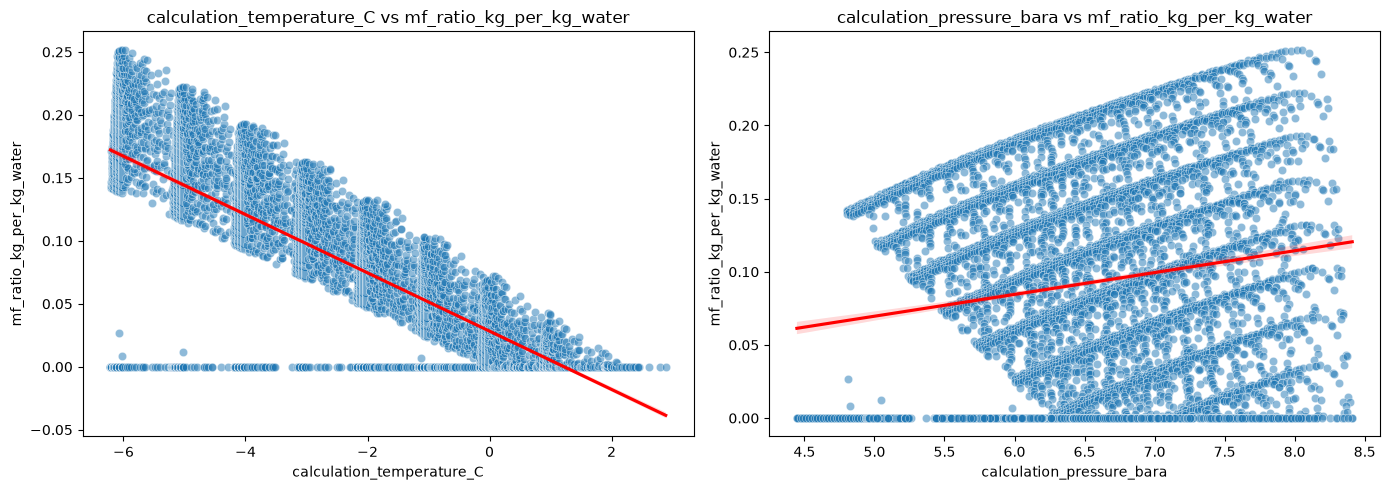

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, feature_columns):
    sns.scatterplot(
        data=df_reg,
        x=col,
        y=target,
        ax=ax,
        alpha=0.5,
    )

    sns.regplot(
        data=df_reg,
        x=col,
        y=target,
        ax=ax,
        scatter=False,
        color="red",
    )
    ax.set_title(f"{col} vs {target}")

plt.tight_layout()

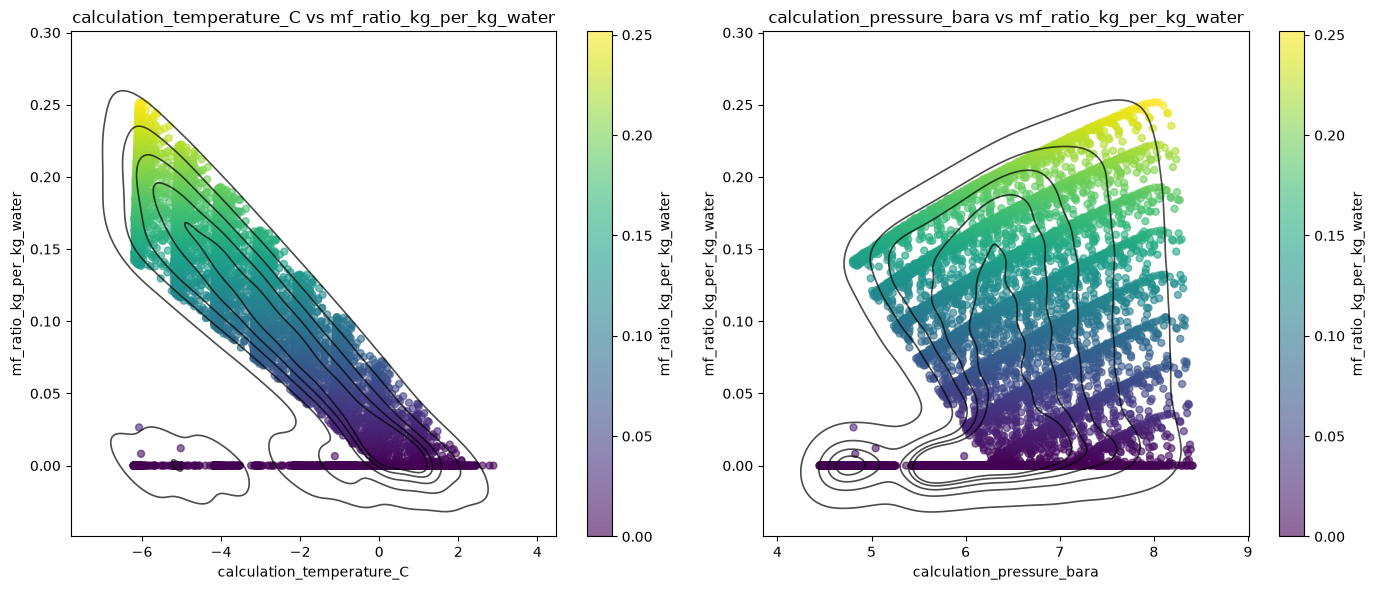

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, col in zip(axes, feature_columns):
    sc = ax.scatter(
        df_reg[col],
        df_reg[target],
        c=df_reg[target],
        cmap="viridis",
        alpha=0.6,
        s=25
    )

    sns.kdeplot(
        data=df_reg,
        x=col,
        y=target,
        ax=ax,
        levels=6,
        color="black",
        linewidths=1.2,
        alpha=0.7
    )
    ax.set_title(f"{col} vs {target}")
    plt.colorbar(sc, ax=ax, label=target)

plt.tight_layout()

In [17]:
import plotly.express as px


fig = px.scatter_3d(
    df_reg,
    x="calculation_temperature_C",
    y="calculation_pressure_bara",
    z=target,
    color=target,
    opacity=0.7,
    size_max=6,
    title="3D: Temperature x Pressure x mf_ratio",
)

fig.update_traces(marker=dict(size=4))
fig.update_layout(width=950, height=750)

### 1.2.3. Профилирование для задачи классификации

#### 1.2.3.1. Круговая диаграмма дисбаланса

In [18]:
target = target_columns[1]

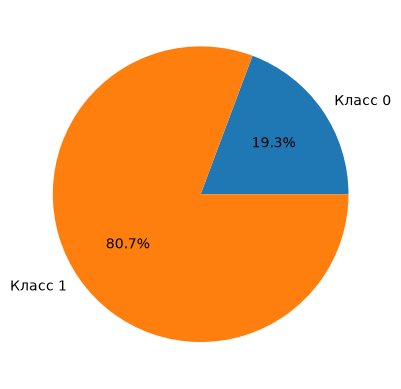

In [19]:
counts = df[target].value_counts().sort_index()
labels = [f"Класс {i}" for i in counts.index]

plt.pie(
    counts,
    labels=labels,
    autopct="%1.1f%%",
)

#### 1.2.3.2. Ящики с усами + гистограммы в разрезе целевого признака

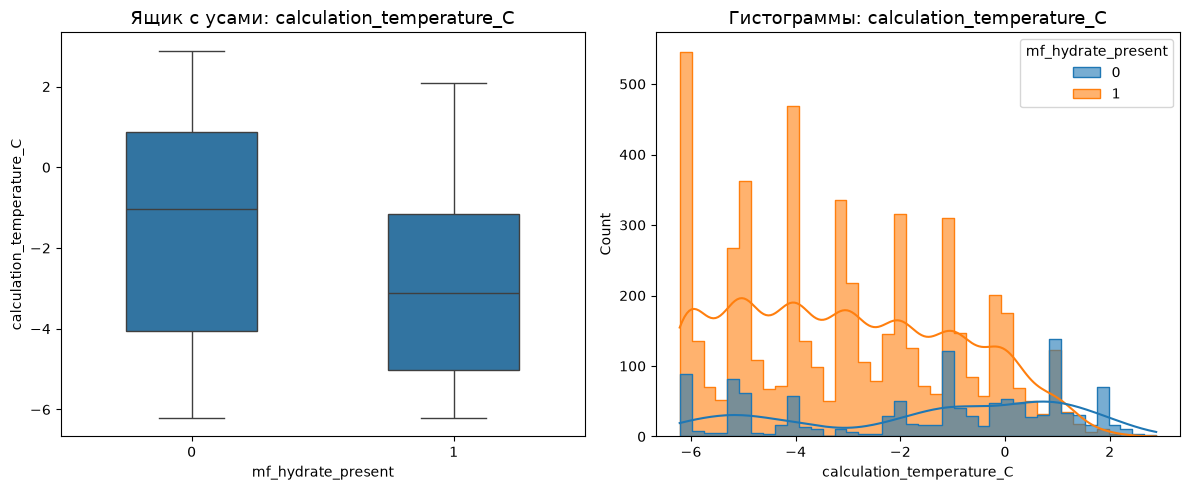

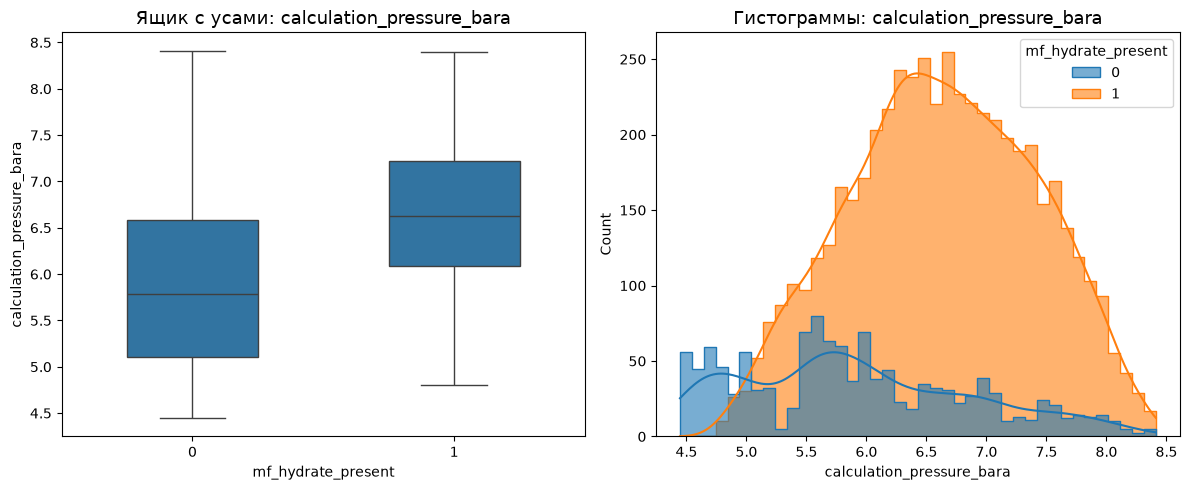

In [20]:
for feature in feature_columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    sns.boxplot(
        data=df,
        x=target,
        y=feature,
        ax=axes[0],
        width=0.5,
    )
    axes[0].set_title(f"Ящик с усами: {feature}", fontsize=13)
    axes[0].set_xlabel(target)
    
    sns.histplot(
        data=df,
        x=feature,
        hue=target,
        ax=axes[1],
        bins=40,
        kde=True,
        element="step",
        alpha=0.6,
        common_norm=False
    )
    
    axes[1].set_title(f"Гистограммы: {feature}", fontsize=13)
    axes[1].set_xlabel(feature)
    
    plt.tight_layout()

#### 1.2.3.3. Скрипичная диаграмма в разрезе целевого признака

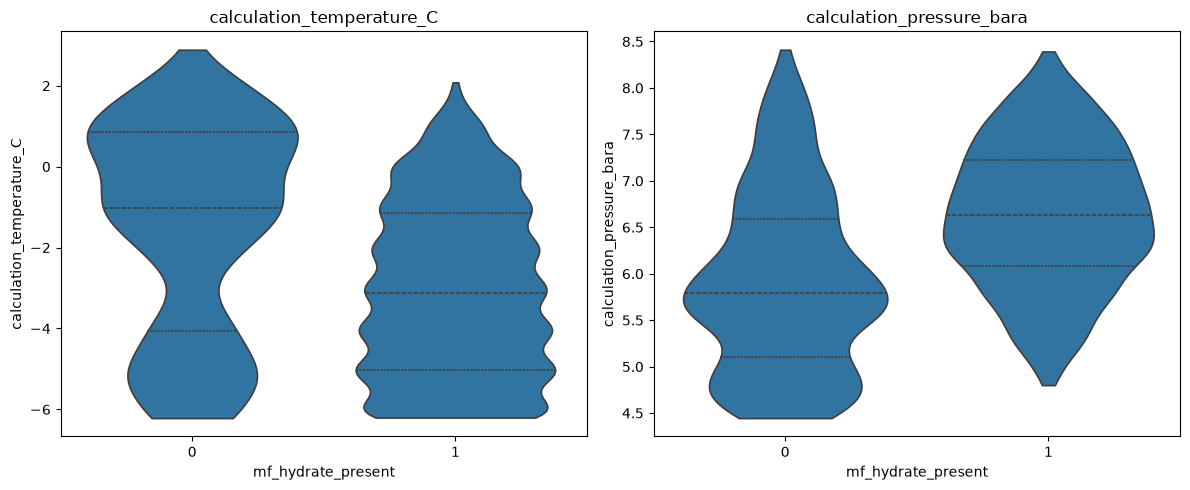

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, col in enumerate(feature_columns):
    sns.violinplot(
        data=df,
        x=target,
        y=col,
        ax=axes[i],
        inner="quartile",
        cut=0
    )
    axes[i].set_title(col)

plt.tight_layout()

#### 1.2.3.4. Проекция целевого признака на плоскость входных признаков

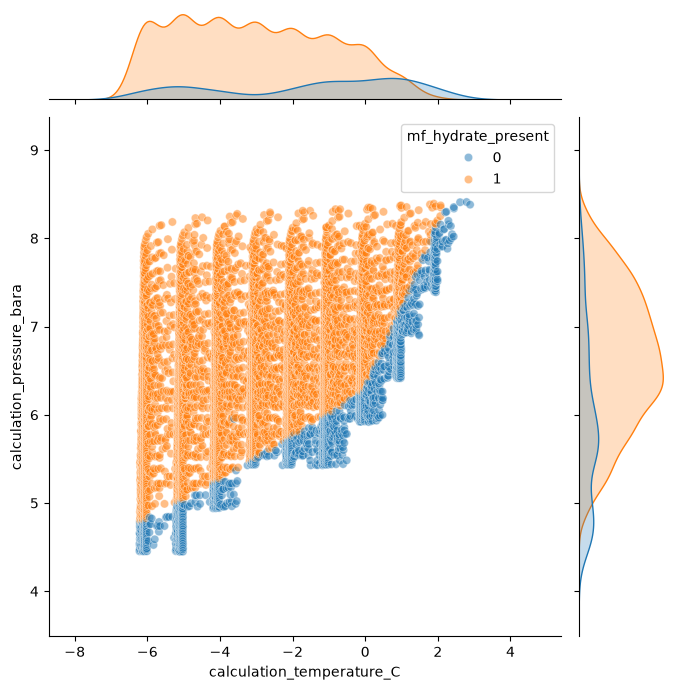

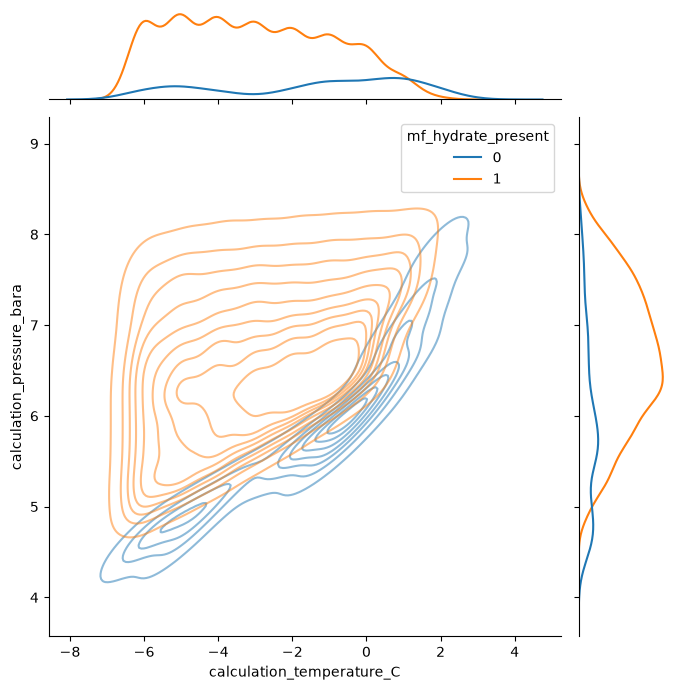

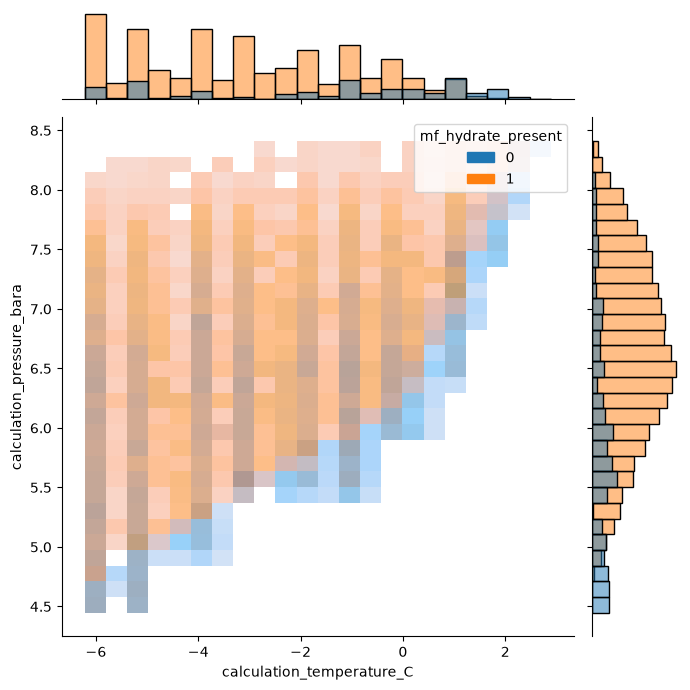

In [22]:
for kind in ["scatter", "kde", "hist"]:
    sns.jointplot(
        data=df,
        x="calculation_temperature_C",
        y="calculation_pressure_bara",
        hue=target,
        kind=kind,
        alpha=0.5,
        height=7,
    )

#### 1.2.3.5. Эмпирическая функция распределения целевого признака в разрезе входных

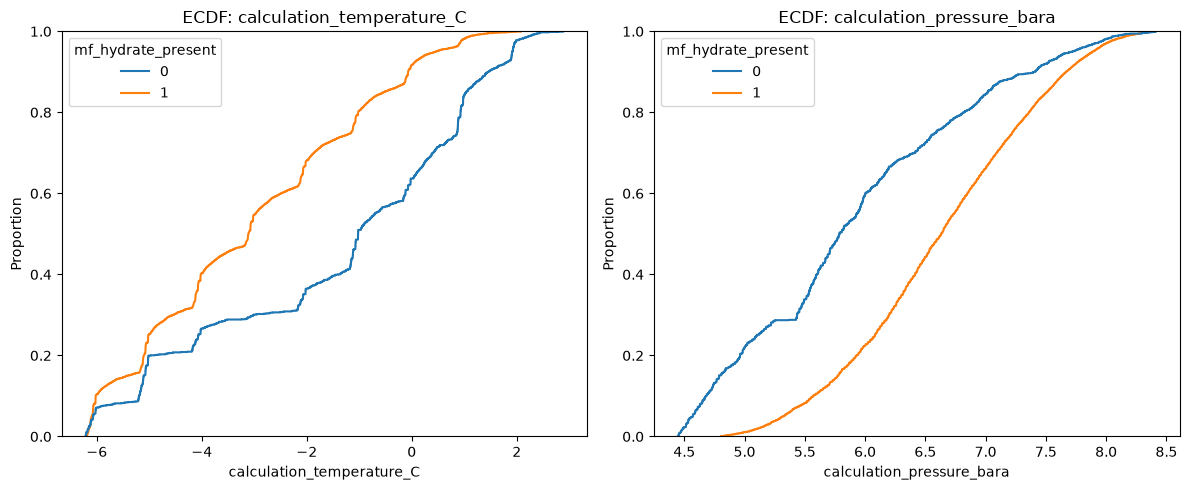

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, col in enumerate(feature_columns):
    sns.ecdfplot(
        data=df,
        x=col,
        hue=target,
        ax=axes[i]
    )
    axes[i].set_title(f"ECDF: {col}")

plt.tight_layout()

## 1.3. Деление выборки на train и test

In [24]:
X = df[feature_columns]
y = df[target_columns]

In [25]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, stratify=y[target_columns[1]], random_state=seed)

In [26]:
y_train['mf_hydrate_present'].value_counts()

mf_hydrate_present
1    4172
0     997
Name: count, dtype: int64

## 1.4. Детекция выбросов и аномалий

### 1.4.1. Графический поиск выбросов

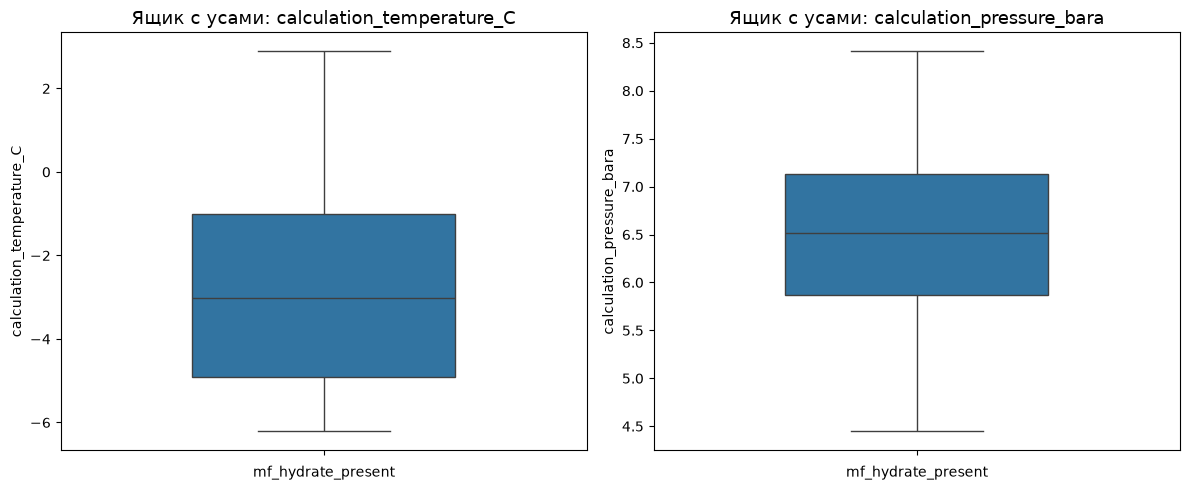

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, feature in enumerate(feature_columns):
    sns.boxplot(
        data=X_train,
        y=feature,
        ax=axes[i],
        width=0.5,
    )
    axes[i].set_title(f"Ящик с усами: {feature}", fontsize=13)
    axes[i].set_xlabel(target)

plt.tight_layout()

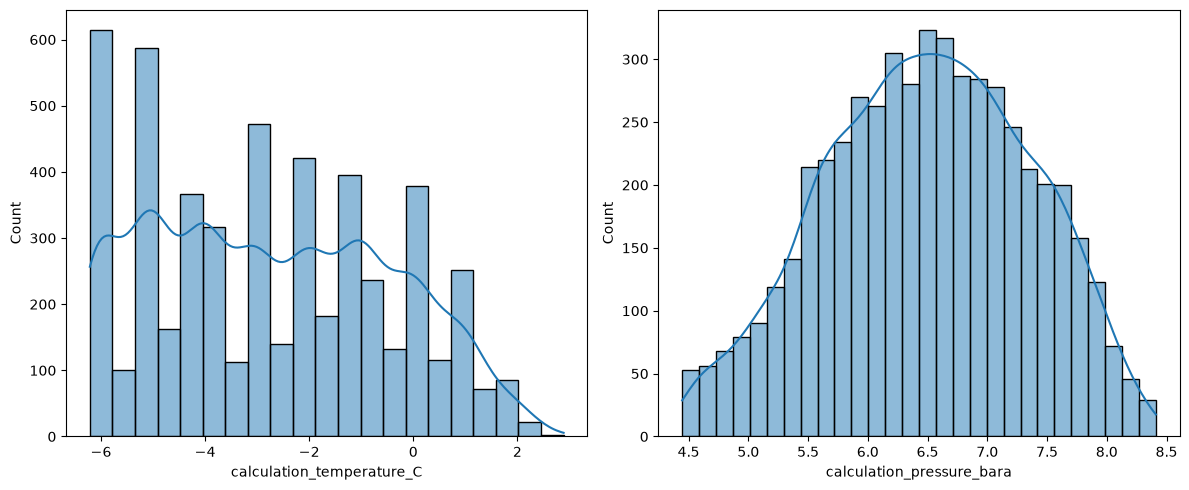

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, feature in enumerate(feature_columns):
    sns.histplot(
        data=X_train,
        x=feature,
        ax=axes[i],
        kde=True,
    )

plt.tight_layout()

### 1.4.2. Поиск аномалий

#### 1.4.2.1. Подготовка данных к детекции аномалий

Для визуализации работа алгоритмов реализуем функцию, которая будет помечать аномальные объекты.

In [29]:
def draw_anomaly(X_2d: np.ndarray[float], anomaly_mask: np.ndarray[bool]) -> None:
    """Визуализация аномальных объектов

    Args:
        X_2d (np.ndarray[float]): Датасет, пониженный до двумерного пространства
        anomaly_mask (np.ndarray[bool]): Маска аномальных объектов
    """
    plt.scatter(X_2d[:, 0], X_2d[:, 1])
    plt.scatter(X_2d[anomaly_mask, 0], X_2d[anomaly_mask, 1], c="red", marker='x')

In [30]:
def draw_anomaly_pie(anomaly_mask: np.ndarray[bool]) -> None:
    """Визуализация долей аномальных и неаномальных объектов в данных

    Args:
        anomaly_mask (np.ndarray[bool]): Маска аномальных объектов
    """
    _, counts = np.unique(anomaly_mask, return_counts=True)

    plt.pie(counts, labels=counts, autopct='%1.0f%%');
    plt.legend([
        'Нормальные объекты', 'Аномалии'
    ], loc='lower right');

#### 1.4.2.2. Isolation Forest

In [31]:
from pyod.models.iforest import IForest


isf = IForest(contamination=0.05).fit(X_train)
isf_anomaly = isf.predict(X_train)

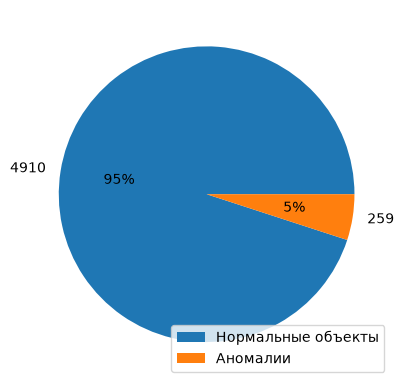

In [32]:
draw_anomaly_pie(isf_anomaly)

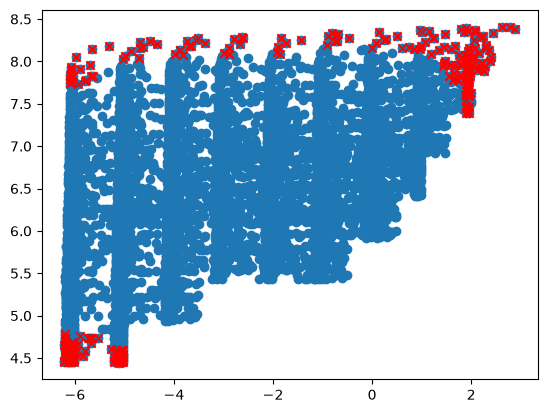

In [33]:
draw_anomaly(X_train.values, isf_anomaly.astype(bool))

#### 1.4.2.3. One-class SVM

In [34]:
from pyod.models.ocsvm import OCSVM


ocsvm = OCSVM(contamination=0.05).fit(X_train)
ocsvm_anomaly = ocsvm.predict(X_train)

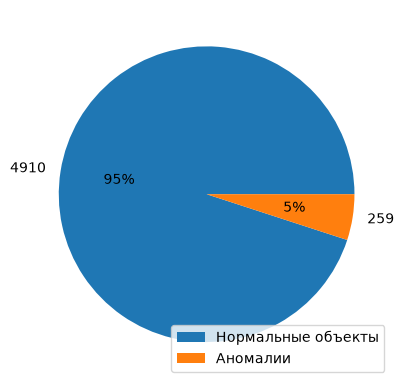

In [35]:
draw_anomaly_pie(ocsvm_anomaly)

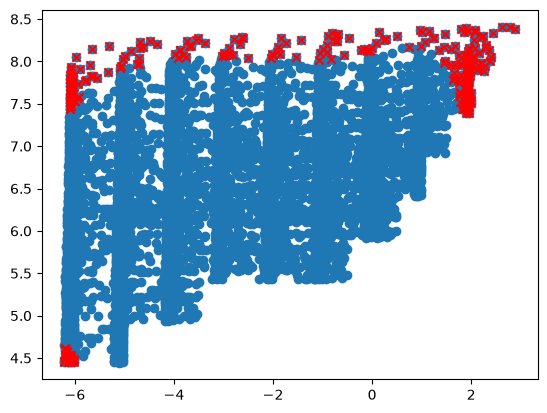

In [36]:
draw_anomaly(X_train.values, ocsvm_anomaly.astype(bool))

#### 1.4.2.4. Удаление аномальных объектов

In [37]:
anomalies = np.all(np.array([
    isf_anomaly,
    ocsvm_anomaly,
]), axis=0)
anomalies

array([False, False, False, ..., False, False, False], shape=(5169,))

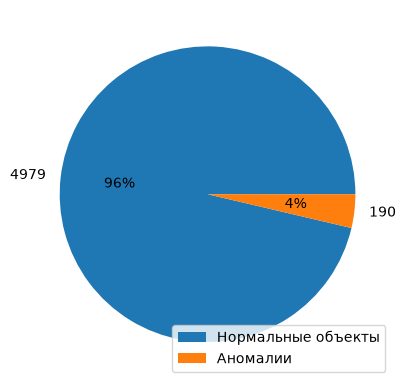

In [38]:
draw_anomaly_pie(anomalies)

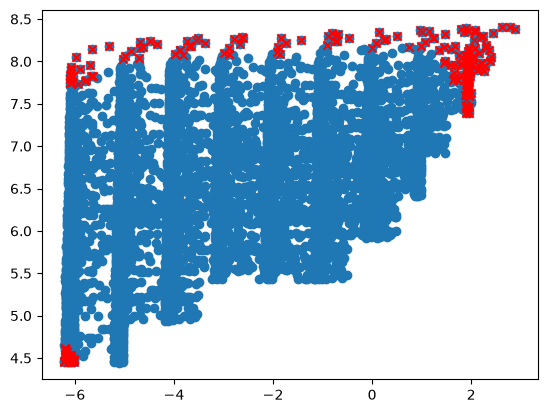

In [39]:
draw_anomaly(X_train.values, anomalies)

# 2. Генерация новых признаков

In [40]:
X_train.describe()

,calculation_temperature_C,calculation_pressure_bara
count,5169.000000,5169.000000
mean,-2.750984,6.492944
std,2.282643,0.856808
min,-6.213607,4.446157
25%,-4.922650,5.867241
50%,-3.018968,6.512880
75%,-0.999231,7.136121
max,2.888214,8.411007


In [41]:
from sklearn.preprocessing import StandardScaler


std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)
X_test_std = std_scaler.transform(X_test)

In [42]:
from sklearn.preprocessing import MinMaxScaler


mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
X_test_mm = mm_scaler.transform(X_test)

In [43]:
from sklearn.preprocessing import RobustScaler


rs_scaler = RobustScaler()
X_train_rs = rs_scaler.fit_transform(X_train)
X_test_rs = rs_scaler.transform(X_test)

# 3. Выбор ML-моделей и метрик

In [44]:
y_train_reg = y_train['mf_ratio_kg_per_kg_water']
y_train_cls = y_train['mf_hydrate_present']

y_test_reg = y_test['mf_ratio_kg_per_kg_water']
y_test_cls = y_test['mf_hydrate_present']

## 3.1. Визуализация зависимостей в данных

### 3.1.1. Визуализация тепловых карт

<Axes: >

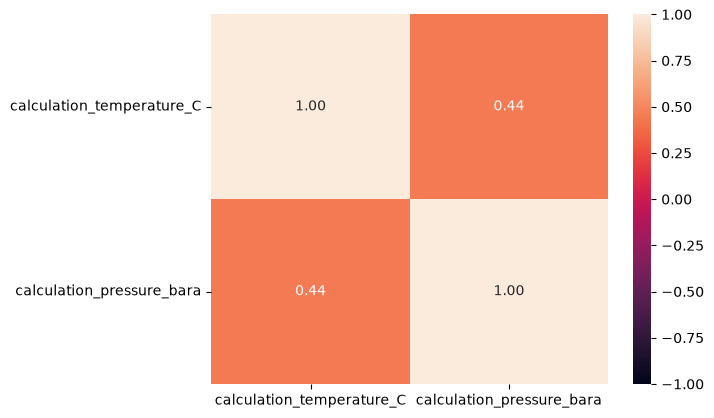

In [45]:
sns.heatmap(
    X_train.corr(),
    vmin=-1, vmax=1,
    annot=True,
    fmt='.2f'
)

<Axes: >

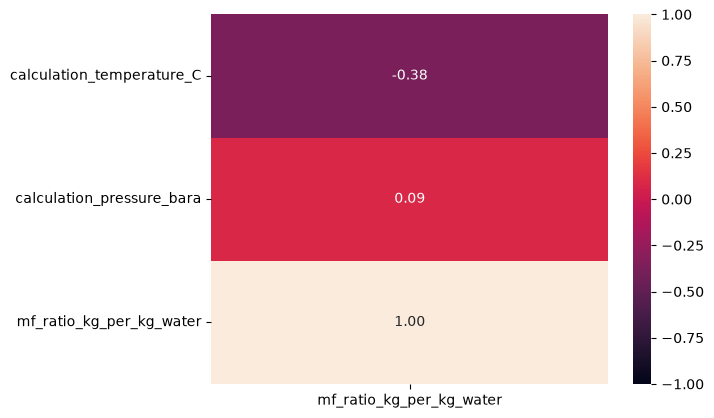

In [46]:
sns.heatmap(
    pd.concat((X_train, y_train_reg), axis=1).corr()[['mf_ratio_kg_per_kg_water']],
    vmin=-1, vmax=1,
    annot=True,
    fmt='.2f'
)

<Axes: >

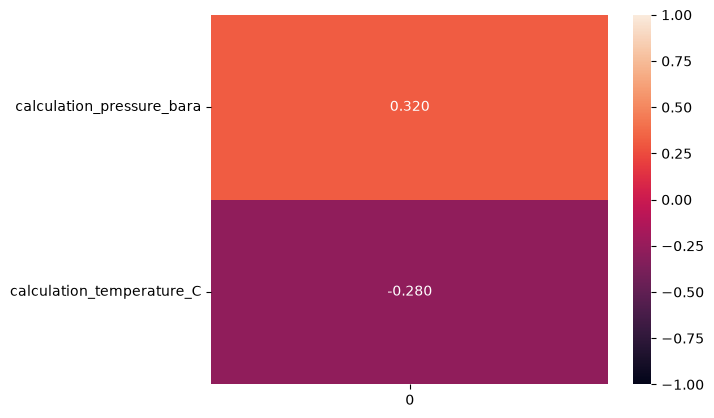

In [47]:
from scipy.stats import pointbiserialr


corrs = {}
for col in feature_columns:
    corr, p_value = pointbiserialr(X_train[col], y_train_cls)
    corrs[col] = corr

corr_series = pd.Series(corrs).sort_values(key=abs, ascending=False)
sns.heatmap(
    pd.DataFrame(corr_series),
    annot=True,
    fmt=".3f",
    vmin=-1, vmax=1,
)

                           F-statistic        p-value
calculation_pressure_bara   589.328246  2.264618e-123
calculation_temperature_C   438.593729   1.531824e-93


<Axes: >

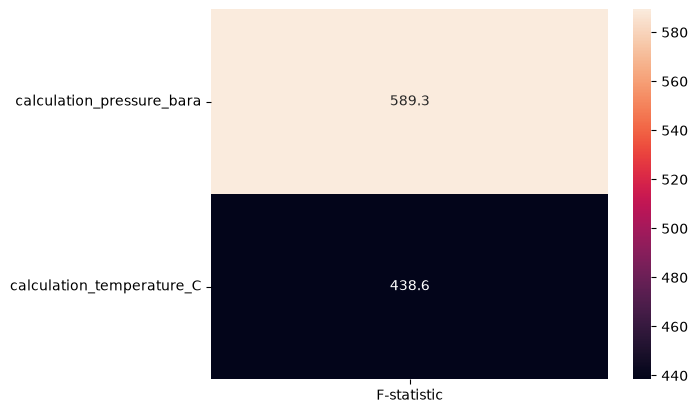

In [48]:
from sklearn.feature_selection import f_classif


f_stat, p_values = f_classif(X_train, y_train_cls)

anova_df = pd.DataFrame({
    "F-statistic": f_stat,
    "p-value": p_values
}, index=feature_columns).sort_values("F-statistic", ascending=False)

print(anova_df)

sns.heatmap(
    anova_df[["F-statistic"]],
    annot=True,
    fmt=".1f",
)

### 3.1.2. Попарные диаграммы рассеяния

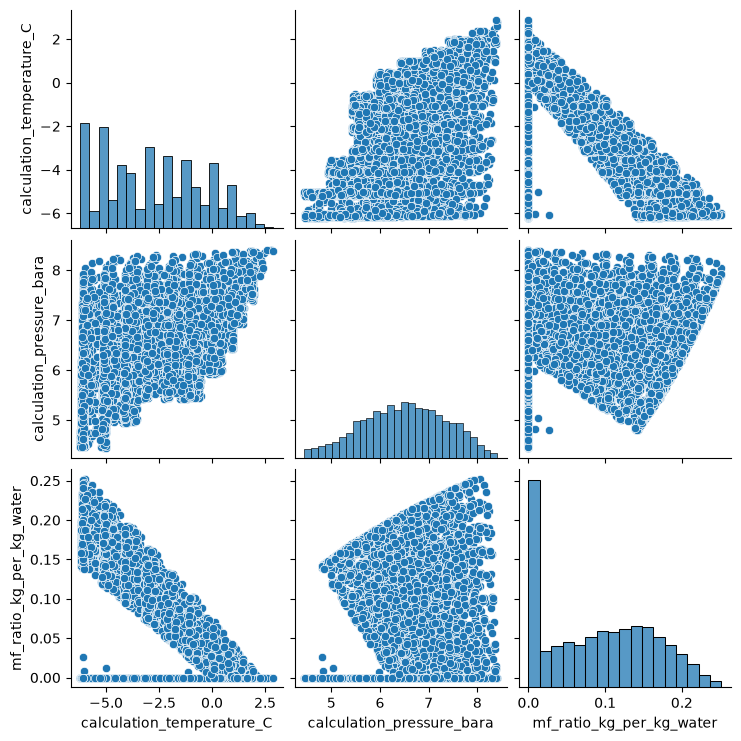

In [49]:
data = pd.concat((X_train, y_train_reg), axis=1)
sns.pairplot(data[data['mf_ratio_kg_per_kg_water'] < 8])

## 3.2. Построение baseline-моделей

In [50]:
from sklearn.dummy import DummyRegressor, DummyClassifier


baseline_reg = DummyRegressor().fit(X_train, y_train_reg)
baseline_cls = DummyClassifier().fit(X_train, y_train_cls)

## 3.3. Подготовка объектов для обучения

In [51]:
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import cross_val_score

### 3.3.1. Для задачи регрессии

#### 3.3.1.1. Обучение ElasticNet

In [52]:
from sklearn.linear_model import ElasticNet

In [53]:
def find_best_elastic_optuna_reg(X, y, n_trials=30, timeout=10800):

    def objective(trial):
        model = ElasticNet(
            alpha=trial.suggest_float("alpha", 1e-4, 10.0, log=True),
            l1_ratio=trial.suggest_float("l1_ratio", 0.05, 0.95),
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="neg_root_mean_squared_error",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

#### 3.3.1.2. Обучение CatBoostRegressor

In [54]:
from catboost import CatBoostRegressor

In [55]:
def find_best_catboost_optuna_reg(X, y, n_trials=30, timeout=10800):
    def objective(trial):
        model = CatBoostRegressor(
            iterations=trial.suggest_int("iterations", 300, 1200, step=300),
            depth=trial.suggest_int("depth", 4, 10),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
            bagging_temperature=trial.suggest_float("bagging_temperature", 0.0, 2.0),
            loss_function="RMSE",
            verbose=0,
            random_seed=seed,
            thread_count=1
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="neg_root_mean_squared_error",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

#### 3.3.1.3. Обучение RandomForestRegressor

In [56]:
from sklearn.ensemble import RandomForestRegressor

In [57]:
def find_best_random_forest_optuna_reg(X, y, n_trials=30, timeout=10800):
    def objective(trial):
        model = RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 800, step=100),
            max_depth=trial.suggest_int("max_depth", 4, 20),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            random_state=seed,
            n_jobs=1
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="neg_root_mean_squared_error",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

### 3.3.2. Для задачи классификации

#### 3.3.2.1. Обучение KNN

In [58]:
from sklearn.neighbors import KNeighborsClassifier

In [59]:
def find_best_knn_optuna_clf(X, y, n_trials=30, timeout=10800):
    def objective(trial):
        model = KNeighborsClassifier(
            n_neighbors=trial.suggest_int("n_neighbors", 3, 15, step=2),
            metric=trial.suggest_categorical("metric", ["euclidean", "manhattan", "minkowski"]),
            p=trial.suggest_int("p", 1, 3),
            n_jobs=1
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="f1",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

#### 3.3.2.2. Обучение LogisticRegression

In [60]:
from sklearn.linear_model import LogisticRegression

In [61]:
def find_best_logistic_optuna_clf(X, y, n_trials=30, timeout=10800):
    def objective(trial):
        model = LogisticRegression(
            C=trial.suggest_float("C", 1e-3, 100, log=True),
            max_iter=trial.suggest_int("max_iter", 200, 1000, step=100),
            random_state=seed,
            n_jobs=1
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="f1",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

#### 3.3.2.3. Обучение CatBoostClassifier

In [62]:
from catboost import CatBoostClassifier

In [63]:
def find_best_catboost_optuna_clf(X, y, n_trials=30, timeout=10800):
    def objective(trial):
        model = CatBoostClassifier(
            iterations=trial.suggest_int("iterations", 300, 1200, step=300),
            depth=trial.suggest_int("depth", 4, 10),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
            bagging_temperature=trial.suggest_float("bagging_temperature", 0.0, 2.0),
            loss_function="Logloss",
            verbose=0,
            random_seed=seed,
            thread_count=1
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="f1",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

#### 3.3.2.4. Обучение RandomForestClassifier

In [64]:
from sklearn.ensemble import RandomForestClassifier

In [65]:
def find_best_random_forest_optuna_clf(X, y, n_trials=30, timeout=10800):
    def objective(trial):
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 800, step=100),
            max_depth=trial.suggest_int("max_depth", 4, 20),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            random_state=seed,
            n_jobs=1
        )

        scores = cross_val_score(
            model,
            X, y,
            cv=5,
            scoring="f1",
        )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=seed, n_startup_trials=10)
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        timeout=timeout,
        show_progress_bar=True,
        gc_after_trial=True,
        n_jobs=-1
    )

    print("Лучшие параметры:", study.best_params)

    return study.best_params

## 3.4. Выбор метрик качества

### 3.4.1. Выбор метрик качества для задачи регрессии

In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

### 3.4.2. Выбор метрик качества для задачи классификации

In [67]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# 4. Обучение ML-моделей и подбор гиперпараметров

## 4.1. Обучение моделей для задачи регрессии

In [71]:
models_reg = {}

### 4.1.1. Обучение ElasticNet

In [ ]:
elastic = ElasticNet(
    **find_best_elastic_optuna_reg(X_train, y_train_cls)
).fit(X_train, y_train_cls)

In [ ]:
elastic_std = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

In [ ]:
elastic_mm = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

In [75]:
elastic_rs = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

[I 2026-11-06 20:39:23,894] A new study created in memory with name: no-name-459c013f-d70d-4ef6-9edc-14cea0766a4c
  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-06 20:39:23,985] Trial 0 finished with value: -0.33853391393375515 and parameters: {'alpha': 0.04227185011749419, 'l1_ratio': 0.6669089051809016}. Best is trial 0 with value: -0.33853391393375515.


Best trial: 10. Best value: -0.32538:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-06 20:39:23,993] Trial 3 finished with value: -0.39455306605639323 and parameters: {'alpha': 0.14839579896030786, 'l1_ratio': 0.8945161672347022}. Best is trial 0 with value: -0.33853391393375515.


Best trial: 9. Best value: -0.325347:   3%|▎         | 1/30 [00:00<00:09,  3.01it/s]

[I 2026-11-06 20:39:23,999] Trial 5 finished with value: -0.39455306605639323 and parameters: {'alpha': 0.5650891225868505, 'l1_ratio': 0.8912582989326407}. Best is trial 0 with value: -0.33853391393375515.


... (50 outputs left out)

Best trial: 23. Best value: -0.325346:  93%|█████████▎| 28/30 [00:03<00:00,  6.18it/s, 2.84/10800 seconds]

[I 2026-11-06 20:39:26,371] Trial 29 finished with value: -0.3254036910920745 and parameters: {'alpha': 0.003591885068946771, 'l1_ratio': 0.3487313606845458}. Best is trial 23 with value: -0.3253458549131463.


Best trial: 23. Best value: -0.325346: 100%|██████████| 30/30 [00:03<00:00,  9.34it/s, 3.12/10800 seconds]

Лучшие параметры: {'alpha': 0.00010162626590844018, 'l1_ratio': 0.13510866036394673}


In [76]:
models_reg['ElasticNet'] = {
    'base': elastic,
    'std': elastic_std,
    'mm': elastic_mm,
    'rs': elastic_rs,
}

### 4.1.2. Обучение CatBoostRegressor

In [77]:
cat_reg = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train, y_train_cls)
).fit(X_train, y_train_cls)

[I 2026-11-06 20:39:27,132] A new study created in memory with name: no-name-acccc9e5-d18c-41df-a787-fb865fb7ddf2
Best trial: 7. Best value: -0.174592:   3%|▎         | 1/30 [00:02<01:19,  2.74s/it, 2.73/10800 seconds]

[I 2026-11-06 20:39:29,696] Trial 7 finished with value: -0.17459245649244168 and parameters: {'iterations': 300, 'depth': 4, 'learning_rate': 0.021646638210399492, 'l2_leaf_reg': 1.2558185665658825, 'bagging_temperature': 1.6394348076126413}. Best is trial 7 with value: -0.17459245649244168.


Best trial: 9. Best value: -0.137413:   7%|▋         | 2/30 [00:03<00:38,  1.38s/it, 3.17/10800 seconds]

[I 2026-11-06 20:39:30,139] Trial 9 finished with value: -0.1374129998770206 and parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.0478807053986742, 'l2_leaf_reg': 6.043759031113303, 'bagging_temperature': 1.6837020026210645}. Best is trial 9 with value: -0.1374129998770206.


Best trial: 2. Best value: -0.137301:  10%|█         | 3/30 [00:04<00:40,  1.50s/it, 4.81/10800 seconds]

[I 2026-11-06 20:39:31,775] Trial 2 finished with value: -0.13730051528447493 and parameters: {'iterations': 600, 'depth': 4, 'learning_rate': 0.028718326277513403, 'l2_leaf_reg': 1.1471558103843398, 'bagging_temperature': 0.7758126805752108}. Best is trial 2 with value: -0.13730051528447493.


... (50 outputs left out)

Best trial: 28. Best value: -0.102652:  97%|█████████▋| 29/30 [02:10<00:19, 19.30s/it, 130.16/10800 seconds]

[I 2026-11-06 20:41:37,193] Trial 6 finished with value: -0.10386267870130209 and parameters: {'iterations': 600, 'depth': 10, 'learning_rate': 0.08086564393304707, 'l2_leaf_reg': 4.811285797713183, 'bagging_temperature': 1.1708198308177278}. Best is trial 28 with value: -0.10265194758571863.


Best trial: 28. Best value: -0.102652: 100%|██████████| 30/30 [04:18<00:00,  8.61s/it, 258.41/10800 seconds]


[I 2026-11-06 20:43:45,421] Trial 12 finished with value: -0.10462021883060764 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.08003538136849421, 'l2_leaf_reg': 9.011327954942962, 'bagging_temperature': 0.47198734907899387}. Best is trial 28 with value: -0.10265194758571863.
Лучшие параметры: {'iterations': 1200, 'depth': 8, 'learning_rate': 0.03996962523042958, 'l2_leaf_reg': 1.4458134984004614, 'bagging_temperature': 0.7941612911925358}
0:	learn: 0.3849760	total: 2.86ms	remaining: 3.43s
1:	learn: 0.3766490	total: 5.12ms	remaining: 3.07s
2:	learn: 0.3676872	total: 7.5ms	remaining: 2.99s
3:	learn: 0.3599806	total: 9.82ms	remaining: 2.94s
4:	learn: 0.3521676	total: 12ms	remaining: 2.88s
5:	learn: 0.3443355	total: 14.6ms	remaining: 2.9s
6:	learn: 0.3370895	total: 17ms	remaining: 2.89s
7:	learn: 0.3301767	total: 19.4ms	remaining: 2.9s
8:	learn: 0.3227343	total: 21.8ms	remaining: 2.88s
9:	learn: 0.3160387	total: 24ms	remaining: 2.85s
10:	learn: 0.3098973	total: 26.8ms	

In [78]:
cat_reg_std = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

[I 2026-11-06 20:43:48,586] A new study created in memory with name: no-name-be7602b1-368f-4280-890a-0d8aec50f249
  0%|          | 0/30 [00:06<?, ?it/s]

[I 2026-11-06 20:43:55,482] Trial 7 finished with value: -0.15877460602633883 and parameters: {'iterations': 900, 'depth': 4, 'learning_rate': 0.010428004609418028, 'l2_leaf_reg': 1.3962793966586908, 'bagging_temperature': 0.9292004978079382}. Best is trial 7 with value: -0.15877460602633883.


Best trial: 10. Best value: -0.11149:   7%|▋         | 2/30 [00:07<01:25,  3.06s/it, 7.33/10800 seconds]

[I 2026-11-06 20:43:55,744] Trial 10 finished with value: -0.11149036247091511 and parameters: {'iterations': 900, 'depth': 4, 'learning_rate': 0.16494344831929272, 'l2_leaf_reg': 1.098582917717132, 'bagging_temperature': 1.0743248503947198}. Best is trial 10 with value: -0.11149036247091511.


Best trial: 10. Best value: -0.11149:   7%|▋         | 2/30 [00:07<01:25,  3.06s/it, 7.33/10800 seconds]

[I 2026-11-06 20:43:56,280] Trial 1 finished with value: -0.14229481010094155 and parameters: {'iterations': 1200, 'depth': 4, 'learning_rate': 0.014683381835503677, 'l2_leaf_reg': 8.084094617485592, 'bagging_temperature': 1.6043379441166548}. Best is trial 10 with value: -0.11149036247091511.


... (50 outputs left out)

Best trial: 14. Best value: -0.105358:  97%|█████████▋| 29/30 [01:33<00:05,  5.47s/it, 93.85/10800 seconds]

[I 2026-11-06 20:45:22,315] Trial 18 finished with value: -0.149425803791573 and parameters: {'iterations': 300, 'depth': 10, 'learning_rate': 0.011849660893615983, 'l2_leaf_reg': 4.4269218323012876, 'bagging_temperature': 1.8714854005586394}. Best is trial 14 with value: -0.1053579940388349.


Best trial: 14. Best value: -0.105358: 100%|██████████| 30/30 [03:14<00:00,  6.48s/it, 194.45/10800 seconds]


[I 2026-11-06 20:47:02,905] Trial 0 finished with value: -0.10772403457860576 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.03229682101917555, 'l2_leaf_reg': 6.387560999160274, 'bagging_temperature': 1.2875280004077088}. Best is trial 14 with value: -0.1053579940388349.
Лучшие параметры: {'iterations': 300, 'depth': 10, 'learning_rate': 0.13144714227919746, 'l2_leaf_reg': 1.5120659933284324, 'bagging_temperature': 1.1678695860839157}
0:	learn: 0.3619308	total: 21.6ms	remaining: 6.45s
1:	learn: 0.3329819	total: 45.2ms	remaining: 6.73s
2:	learn: 0.3060055	total: 68.4ms	remaining: 6.77s
3:	learn: 0.2845716	total: 92.3ms	remaining: 6.83s
4:	learn: 0.2664965	total: 116ms	remaining: 6.84s
5:	learn: 0.2485013	total: 140ms	remaining: 6.88s
6:	learn: 0.2362379	total: 165ms	remaining: 6.89s
7:	learn: 0.2235934	total: 188ms	remaining: 6.85s
8:	learn: 0.2126441	total: 211ms	remaining: 6.83s
9:	learn: 0.2045027	total: 234ms	remaining: 6.77s
10:	learn: 0.1968023	total: 256ms	re

In [79]:
cat_reg_mm = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

[I 2026-11-06 20:47:10,195] A new study created in memory with name: no-name-a86a90cd-2c43-40da-9c85-614adbfe45dd
Best trial: 10. Best value: -0.146958:   3%|▎         | 1/30 [00:02<01:14,  2.56s/it, 2.56/10800 seconds]

[I 2026-11-06 20:47:12,585] Trial 10 finished with value: -0.14695777930157503 and parameters: {'iterations': 300, 'depth': 4, 'learning_rate': 0.046689831384235325, 'l2_leaf_reg': 5.333419163924442, 'bagging_temperature': 0.4224102104466054}. Best is trial 10 with value: -0.14695777930157503.


Best trial: 10. Best value: -0.146958:   3%|▎         | 1/30 [00:09<01:14,  2.56s/it, 2.56/10800 seconds]

[I 2026-11-06 20:47:19,352] Trial 1 finished with value: -0.11223941999838916 and parameters: {'iterations': 1200, 'depth': 5, 'learning_rate': 0.04133392810591382, 'l2_leaf_reg': 3.256478338148168, 'bagging_temperature': 1.7449018837240244}. Best is trial 1 with value: -0.11223941999838916.


Best trial: 5. Best value: -0.106819:   7%|▋         | 2/30 [00:12<02:21,  5.05s/it, 9.34/10800 seconds] 

[I 2026-11-06 20:47:22,469] Trial 5 finished with value: -0.10681863795681781 and parameters: {'iterations': 1200, 'depth': 6, 'learning_rate': 0.05522750259443442, 'l2_leaf_reg': 2.7610906226497796, 'bagging_temperature': 1.8532876413443649}. Best is trial 5 with value: -0.10681863795681781.


... (48 outputs left out)

Best trial: 9. Best value: -0.105045:  97%|█████████▋| 29/30 [04:13<00:42, 42.30s/it, 253.52/10800 seconds]

[I 2026-11-06 20:51:23,585] Trial 3 finished with value: -0.10702363456440996 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.07983838814573725, 'l2_leaf_reg': 3.469831205875778, 'bagging_temperature': 1.6755983614737289}. Best is trial 9 with value: -0.10504498098867303.


Best trial: 9. Best value: -0.105045: 100%|██████████| 30/30 [04:22<00:00,  8.75s/it, 262.63/10800 seconds]


[I 2026-11-06 20:51:32,726] Trial 15 finished with value: -0.11139582091089117 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.01854497287055758, 'l2_leaf_reg': 6.430013036232384, 'bagging_temperature': 0.9217254903951637}. Best is trial 9 with value: -0.10504498098867303.
Лучшие параметры: {'iterations': 900, 'depth': 9, 'learning_rate': 0.0967967338916221, 'l2_leaf_reg': 1.9617925225636101, 'bagging_temperature': 0.6920325021081601}
0:	learn: 0.3704634	total: 4.42ms	remaining: 3.98s
1:	learn: 0.3488228	total: 8.12ms	remaining: 3.64s
2:	learn: 0.3303634	total: 11.5ms	remaining: 3.44s
3:	learn: 0.3132620	total: 15ms	remaining: 3.36s
4:	learn: 0.2979918	total: 18.5ms	remaining: 3.31s
5:	learn: 0.2836514	total: 22.1ms	remaining: 3.29s
6:	learn: 0.2703006	total: 25.6ms	remaining: 3.27s
7:	learn: 0.2593209	total: 29.2ms	remaining: 3.25s
8:	learn: 0.2491509	total: 32.8ms	remaining: 3.25s
9:	learn: 0.2404760	total: 36.4ms	remaining: 3.24s
10:	learn: 0.2325277	total: 40.1

In [ ]:
cat_reg_rs = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

[I 2026-11-06 20:51:36,293] A new study created in memory with name: no-name-75e07c72-ae45-429b-958c-3b0b078d0109
  0%|          | 0/30 [00:02<?, ?it/s]

[I 2026-11-06 20:51:38,955] Trial 6 finished with value: -0.11425828097018005 and parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.14621749057973693, 'l2_leaf_reg': 6.768707795686762, 'bagging_temperature': 1.3611200286630674}. Best is trial 6 with value: -0.11425828097018005.


Best trial: 6. Best value: -0.114258:   3%|▎         | 1/30 [00:02<01:22,  2.85s/it, 2.85/10800 seconds]

[I 2026-11-06 20:51:39,158] Trial 9 finished with value: -0.11842187937085351 and parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.08666571167394593, 'l2_leaf_reg': 2.941902334132745, 'bagging_temperature': 0.03652801694175056}. Best is trial 6 with value: -0.11425828097018005.
[I 2026-11-06 20:51:39,160] Trial 1 finished with value: -0.14807394351936268 and parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.029038416561896097, 'l2_leaf_reg': 1.2312787099966143, 'bagging_temperature': 0.2486379748619807}. Best is trial 6 with value: -0.11425828097018005.


Best trial: 7. Best value: -0.111283:  13%|█▎        | 4/30 [00:05<00:25,  1.01it/s, 5.02/10800 seconds]

[I 2026-11-06 20:51:41,147] Trial 7 finished with value: -0.11128333595040787 and parameters: {'iterations': 300, 'depth': 7, 'learning_rate': 0.15533752234280415, 'l2_leaf_reg': 8.97398930560904, 'bagging_temperature': 1.7081854254821123}. Best is trial 7 with value: -0.11128333595040787.


... (38 outputs left out)

Best trial: 21. Best value: -0.107556:  87%|████████▋ | 26/30 [00:32<00:06,  1.60s/it, 32.93/10800 seconds]

[I 2026-11-06 20:52:09,102] Trial 21 finished with value: -0.10755630741317648 and parameters: {'iterations': 900, 'depth': 8, 'learning_rate': 0.13390086941945994, 'l2_leaf_reg': 2.609795219772153, 'bagging_temperature': 1.1355403997534794}. Best is trial 21 with value: -0.10755630741317648.


Best trial: 21. Best value: -0.107556:  90%|█████████ | 27/30 [00:35<00:05,  1.84s/it, 35.35/10800 seconds]

[I 2026-11-06 20:52:11,528] Trial 0 finished with value: -0.11841826279126011 and parameters: {'iterations': 900, 'depth': 9, 'learning_rate': 0.012317455464280482, 'l2_leaf_reg': 1.2823308165957694, 'bagging_temperature': 1.5434151163689374}. Best is trial 21 with value: -0.10755630741317648.


In [ ]:
models_reg['CatBoostRegressor'] = {
    'base': cat_reg,
    'std': cat_reg_std,
    'mm': cat_reg_mm,
    'rs': cat_reg_rs,
}

### 4.1.3. Обучение RandomForestRegressor

In [ ]:
rf_reg = RandomForestRegressor(
    **find_best_random_forest_optuna_reg(X_train, y_train_cls)
).fit(X_train, y_train_cls)

[I 2026-11-05 22:01:45,201] A new study created in memory with name: no-name-25514114-5dec-4882-8f49-b4a21ef073db
  0%|          | 0/30 [00:06<?, ?it/s]

[I 2026-11-05 22:01:51,305] Trial 10 finished with value: -0.1160488580343143 and parameters: {'n_estimators': 100, 'max_depth': 13, 'min_samples_split': 2, 'min_samples_leaf': 8}. Best is trial 10 with value: -0.1160488580343143.


Best trial: 7. Best value: -0.106964:   7%|▋         | 2/30 [00:06<01:19,  2.83s/it, 6.33/10800 seconds] 

[I 2026-11-05 22:01:51,712] Trial 7 finished with value: -0.10696363929948935 and parameters: {'n_estimators': 100, 'max_depth': 10, 'min_samples_split': 8, 'min_samples_leaf': 4}. Best is trial 7 with value: -0.10696363929948935.


Best trial: 7. Best value: -0.106964:   7%|▋         | 2/30 [00:17<01:19,  2.83s/it, 6.70/10800 seconds]

[I 2026-11-05 22:02:02,839] Trial 3 finished with value: -0.10828878749778728 and parameters: {'n_estimators': 300, 'max_depth': 11, 'min_samples_split': 11, 'min_samples_leaf': 4}. Best is trial 7 with value: -0.10696363929948935.


... (46 outputs left out)

Best trial: 21. Best value: -0.103327:  97%|█████████▋| 29/30 [00:54<00:00,  1.84it/s, 54.70/10800 seconds]

[I 2026-11-05 22:02:39,738] Trial 19 finished with value: -0.105868292768455 and parameters: {'n_estimators': 500, 'max_depth': 19, 'min_samples_split': 2, 'min_samples_leaf': 4}. Best is trial 21 with value: -0.103326674528134.


Best trial: 21. Best value: -0.103327: 100%|██████████| 30/30 [00:56<00:00,  1.87s/it, 56.04/10800 seconds]


[I 2026-11-05 22:02:41,073] Trial 18 finished with value: -0.10555114834971709 and parameters: {'n_estimators': 600, 'max_depth': 19, 'min_samples_split': 10, 'min_samples_leaf': 2}. Best is trial 21 with value: -0.103326674528134.
Лучшие параметры: {'n_estimators': 100, 'max_depth': 10, 'min_samples_split': 7, 'min_samples_leaf': 2}


In [ ]:
rf_reg_std = RandomForestRegressor(
    **find_best_random_forest_optuna_reg(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

[I 2026-11-05 22:02:41,566] A new study created in memory with name: no-name-b3d5be41-f6d0-4c34-b397-4e23626f8b1b
Best trial: 7. Best value: -0.130806:   0%|          | 0/30 [00:06<?, ?it/s]

[I 2026-11-05 22:02:47,578] Trial 7 finished with value: -0.13080558226858946 and parameters: {'n_estimators': 100, 'max_depth': 6, 'min_samples_split': 10, 'min_samples_leaf': 5}. Best is trial 7 with value: -0.13080558226858946.


Best trial: 7. Best value: -0.130806:   3%|▎         | 1/30 [00:16<03:00,  6.22s/it, 6.22/10800 seconds]

[I 2026-11-05 22:02:58,254] Trial 6 finished with value: -0.13383893999001428 and parameters: {'n_estimators': 300, 'max_depth': 6, 'min_samples_split': 4, 'min_samples_leaf': 10}. Best is trial 7 with value: -0.13080558226858946.


Best trial: 7. Best value: -0.130806:   7%|▋         | 2/30 [00:16<04:07,  8.83s/it, 16.88/10800 seconds]

[I 2026-11-05 22:02:58,535] Trial 1 finished with value: -0.11979083858140535 and parameters: {'n_estimators': 300, 'max_depth': 7, 'min_samples_split': 13, 'min_samples_leaf': 6}. Best is trial 1 with value: -0.11979083858140535.


... (50 outputs left out)

Best trial: 10. Best value: -0.0981254:  97%|█████████▋| 29/30 [01:11<00:01,  1.73s/it, 71.47/10800 seconds]

[I 2026-11-05 22:03:52,867] Trial 26 finished with value: -0.09948968813973286 and parameters: {'n_estimators': 800, 'max_depth': 9, 'min_samples_split': 2, 'min_samples_leaf': 1}. Best is trial 10 with value: -0.0981254481603575.


Best trial: 10. Best value: -0.0981254: 100%|██████████| 30/30 [01:11<00:00,  2.39s/it, 71.67/10800 seconds]


[I 2026-11-05 22:03:53,077] Trial 29 finished with value: -0.09936320672911282 and parameters: {'n_estimators': 700, 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 2}. Best is trial 10 with value: -0.0981254481603575.
Лучшие параметры: {'n_estimators': 600, 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1}


In [ ]:
rf_reg_mm = RandomForestRegressor(
    **find_best_random_forest_optuna_reg(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

[I 2026-11-05 22:03:55,054] A new study created in memory with name: no-name-7d472337-179e-4cc3-9654-df3d2eabbc1e
Best trial: 0. Best value: -0.111293:   3%|▎         | 1/30 [00:11<05:29, 11.35s/it]

[I 2026-11-05 22:04:06,135] Trial 0 finished with value: -0.11129347324128828 and parameters: {'n_estimators': 200, 'max_depth': 13, 'min_samples_split': 2, 'min_samples_leaf': 6}. Best is trial 0 with value: -0.11129347324128828.


Best trial: 10. Best value: -0.106078:   7%|▋         | 2/30 [00:11<02:17,  4.90s/it, 11.72/10800 seconds]

[I 2026-11-05 22:04:06,586] Trial 10 finished with value: -0.10607822584891743 and parameters: {'n_estimators': 200, 'max_depth': 19, 'min_samples_split': 5, 'min_samples_leaf': 4}. Best is trial 10 with value: -0.10607822584891743.


Best trial: 10. Best value: -0.106078:  10%|█         | 3/30 [00:12<01:16,  2.84s/it, 11.72/10800 seconds]

[I 2026-11-05 22:04:06,906] Trial 6 finished with value: -0.11352997933780215 and parameters: {'n_estimators': 200, 'max_depth': 18, 'min_samples_split': 8, 'min_samples_leaf': 7}. Best is trial 10 with value: -0.10607822584891743.


... (51 outputs left out)

Best trial: 7. Best value: -0.0983096:  97%|█████████▋| 29/30 [01:10<00:01,  1.65s/it, 68.75/10800 seconds]

[I 2026-11-05 22:05:05,313] Trial 29 finished with value: -0.10409967522194155 and parameters: {'n_estimators': 800, 'max_depth': 11, 'min_samples_split': 9, 'min_samples_leaf': 1}. Best is trial 7 with value: -0.09830961688512004.


Best trial: 7. Best value: -0.0983096: 100%|██████████| 30/30 [01:10<00:00,  2.35s/it, 70.45/10800 seconds]


Лучшие параметры: {'n_estimators': 400, 'max_depth': 13, 'min_samples_split': 2, 'min_samples_leaf': 1}


In [ ]:
rf_reg_rs = RandomForestRegressor(
    **find_best_random_forest_optuna_reg(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

[I 2026-11-05 22:05:06,704] A new study created in memory with name: no-name-2f5fd61c-d3a0-4f23-b9f0-e30d61e3f017
Best trial: 4. Best value: -0.108539:   0%|          | 0/30 [00:06<?, ?it/s]

[I 2026-11-05 22:05:12,539] Trial 4 finished with value: -0.10853945551304642 and parameters: {'n_estimators': 100, 'max_depth': 19, 'min_samples_split': 12, 'min_samples_leaf': 2}. Best is trial 4 with value: -0.10853945551304642.


Best trial: 4. Best value: -0.108539:   3%|▎         | 1/30 [00:16<02:55,  6.04s/it, 6.03/10800 seconds]

[I 2026-11-05 22:05:23,290] Trial 12 finished with value: -0.20530785728141138 and parameters: {'n_estimators': 200, 'max_depth': 4, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 4 with value: -0.10853945551304642.


Best trial: 4. Best value: -0.108539:   7%|▋         | 2/30 [00:17<04:06,  8.81s/it, 16.79/10800 seconds]

[I 2026-11-05 22:05:23,594] Trial 6 finished with value: -0.11604254018997462 and parameters: {'n_estimators': 300, 'max_depth': 13, 'min_samples_split': 20, 'min_samples_leaf': 6}. Best is trial 4 with value: -0.10853945551304642.


... (50 outputs left out)

Best trial: 26. Best value: -0.0984175:  97%|█████████▋| 29/30 [00:58<00:01,  1.09s/it, 58.23/10800 seconds]

[I 2026-11-05 22:06:04,773] Trial 28 finished with value: -0.10510723651050038 and parameters: {'n_estimators': 500, 'max_depth': 15, 'min_samples_split': 10, 'min_samples_leaf': 1}. Best is trial 26 with value: -0.09841753274733055.


Best trial: 26. Best value: -0.0984175: 100%|██████████| 30/30 [00:59<00:00,  1.99s/it, 59.55/10800 seconds]


[I 2026-11-05 22:06:06,091] Trial 24 finished with value: -0.10267587424844186 and parameters: {'n_estimators': 700, 'max_depth': 15, 'min_samples_split': 4, 'min_samples_leaf': 3}. Best is trial 26 with value: -0.09841753274733055.
Лучшие параметры: {'n_estimators': 300, 'max_depth': 13, 'min_samples_split': 4, 'min_samples_leaf': 1}


In [ ]:
models_reg['RandomForestRegressor'] = {
    'base': rf_reg,
    'std': rf_reg_std,
    'mm': rf_reg_mm,
    'rs': rf_reg_rs,
}

## 4.2. Обучение моделей для задачи классификации

In [132]:
models_clf = {}

### 4.2.1. Обучение KNN

In [133]:
knn = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train, y_train_cls)
).fit(X_train, y_train_cls)

[I 2026-11-05 19:58:14,023] A new study created in memory with name: no-name-3d694006-a212-4243-99f0-265cf362b450
  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 19:58:14,489] Trial 0 finished with value: 0.9913919275007347 and parameters: {'n_neighbors': 15, 'metric': 'euclidean', 'p': 1}. Best is trial 0 with value: 0.9913919275007347.


Best trial: 2. Best value: 0.991398:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 19:58:14,493] Trial 3 finished with value: 0.991384322852182 and parameters: {'n_neighbors': 9, 'metric': 'minkowski', 'p': 2}. Best is trial 0 with value: 0.9913919275007347.


Best trial: 11. Best value: 0.99306:   7%|▋         | 2/30 [00:01<00:16,  1.73it/s, 0.91/10800 seconds]

[I 2026-11-05 19:58:14,514] Trial 1 finished with value: 0.9909111651465505 and parameters: {'n_neighbors': 15, 'metric': 'minkowski', 'p': 1}. Best is trial 0 with value: 0.9913919275007347.
[I 2026-11-05 19:58:14,515] Trial 8 finished with value: 0.991384322852182 and parameters: {'n_neighbors': 9, 'metric': 'euclidean', 'p': 3}. Best is trial 0 with value: 0.9913919275007347.


... (35 outputs left out)

Best trial: 11. Best value: 0.99306:  90%|█████████ | 27/30 [00:05<00:00,  4.81it/s, 5.64/10800 seconds]

[I 2026-11-05 19:58:19,356] Trial 27 finished with value: 0.9930601847674533 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 1}. Best is trial 11 with value: 0.9930601847674533.
[I 2026-11-05 19:58:19,664] Trial 28 finished with value: 0.9921070489231674 and parameters: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 2}. Best is trial 11 with value: 0.9930601847674533.


Best trial: 11. Best value: 0.99306: 100%|██████████| 30/30 [00:06<00:00,  4.92it/s, 6.10/10800 seconds]

[I 2026-11-05 19:58:19,825] Trial 29 finished with value: 0.9918770599486166 and parameters: {'n_neighbors': 9, 'metric': 'minkowski', 'p': 1}. Best is trial 11 with value: 0.9930601847674533.
Лучшие параметры: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 1}


In [134]:
knn_std = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

[I 2026-11-05 19:58:24,363] A new study created in memory with name: no-name-53ae1faf-5e57-4194-b118-5c8189d0e241
  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 19:58:24,748] Trial 2 finished with value: 0.9931696363350971 and parameters: {'n_neighbors': 3, 'metric': 'euclidean', 'p': 3}. Best is trial 2 with value: 0.9931696363350971.


Best trial: 3. Best value: 0.993528:   3%|▎         | 1/30 [00:00<00:19,  1.51it/s]

[I 2026-11-05 19:58:24,762] Trial 3 finished with value: 0.9935281393439181 and parameters: {'n_neighbors': 5, 'metric': 'euclidean', 'p': 1}. Best is trial 3 with value: 0.9935281393439181.


Best trial: 11. Best value: 0.993649:  10%|█         | 3/30 [00:01<00:07,  3.48it/s, 0.64/10800 seconds]

[I 2026-11-05 19:58:24,778] Trial 5 finished with value: 0.9935281393439181 and parameters: {'n_neighbors': 5, 'metric': 'euclidean', 'p': 2}. Best is trial 3 with value: 0.9935281393439181.
[I 2026-11-05 19:58:24,803] Trial 7 finished with value: 0.9918680908265032 and parameters: {'n_neighbors': 13, 'metric': 'euclidean', 'p': 1}. Best is trial 3 with value: 0.9935281393439181.


... (39 outputs left out)

Best trial: 14. Best value: 0.993888:  97%|█████████▋| 29/30 [00:05<00:00,  5.88it/s, 5.99/10800 seconds]

[I 2026-11-05 19:58:30,032] Trial 28 finished with value: 0.9935281393439181 and parameters: {'n_neighbors': 5, 'metric': 'euclidean', 'p': 3}. Best is trial 14 with value: 0.9938884486488233.
[I 2026-11-05 19:58:30,356] Trial 29 finished with value: 0.992446881793535 and parameters: {'n_neighbors': 9, 'metric': 'minkowski', 'p': 3}. Best is trial 14 with value: 0.9938884486488233.


Best trial: 14. Best value: 0.993888: 100%|██████████| 30/30 [00:06<00:00,  4.88it/s, 6.14/10800 seconds]

Лучшие параметры: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 2}


In [135]:
knn_mm = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

[I 2026-11-05 19:58:31,941] A new study created in memory with name: no-name-cab4a459-ea04-46d6-86e6-5e07f62ecafc
Best trial: 8. Best value: 0.99353:   3%|▎         | 1/30 [00:00<00:17,  1.67it/s]

[I 2026-11-05 19:58:32,344] Trial 7 finished with value: 0.9931629895559582 and parameters: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 3}. Best is trial 7 with value: 0.9931629895559582.
[I 2026-11-05 19:58:32,358] Trial 3 finished with value: 0.9916326018441092 and parameters: {'n_neighbors': 15, 'metric': 'manhattan', 'p': 3}. Best is trial 7 with value: 0.9931629895559582.


Best trial: 2. Best value: 0.993646:  10%|█         | 3/30 [00:01<00:07,  3.82it/s, 0.76/10800 seconds]

[I 2026-11-05 19:58:32,358] Trial 5 finished with value: 0.9918607815893973 and parameters: {'n_neighbors': 11, 'metric': 'manhattan', 'p': 3}. Best is trial 7 with value: 0.9931629895559582.
[I 2026-11-05 19:58:32,367] Trial 8 finished with value: 0.9935295492366695 and parameters: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 1}. Best is trial 8 with value: 0.9935295492366695.


Best trial: 2. Best value: 0.993646:  13%|█▎        | 4/30 [00:01<00:05,  4.52it/s, 1.08/10800 seconds]

[I 2026-11-05 19:58:32,378] Trial 11 finished with value: 0.9916278345525378 and parameters: {'n_neighbors': 13, 'metric': 'manhattan', 'p': 1}. Best is trial 8 with value: 0.9935295492366695.
[I 2026-11-05 19:58:32,538] Trial 0 finished with value: 0.9918607815893973 and parameters: {'n_neighbors': 11, 'metric': 'minkowski', 'p': 1}. Best is trial 8 with value: 0.9935295492366695.


... (34 outputs left out)

Best trial: 25. Best value: 0.994009:  90%|█████████ | 27/30 [00:05<00:00,  5.26it/s, 5.38/10800 seconds]

[I 2026-11-05 19:58:36,966] Trial 27 finished with value: 0.9936460728511649 and parameters: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 2}. Best is trial 25 with value: 0.9940087159416429.
[I 2026-11-05 19:58:37,330] Trial 28 finished with value: 0.9917405736601317 and parameters: {'n_neighbors': 13, 'metric': 'minkowski', 'p': 2}. Best is trial 25 with value: 0.9940087159416429.


Best trial: 25. Best value: 0.994009: 100%|██████████| 30/30 [00:05<00:00,  5.00it/s, 5.99/10800 seconds]

[I 2026-11-05 19:58:37,638] Trial 29 finished with value: 0.9931669657760412 and parameters: {'n_neighbors': 9, 'metric': 'minkowski', 'p': 2}. Best is trial 25 with value: 0.9940087159416429.
Лучшие параметры: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 3}


In [136]:
knn_rs = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

[I 2026-11-05 19:58:39,142] A new study created in memory with name: no-name-38b3a9a8-c605-4d74-b5b5-d209852b8db1
Best trial: 0. Best value: 0.993287:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 19:58:39,485] Trial 0 finished with value: 0.9932868372052173 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 3}. Best is trial 0 with value: 0.9932868372052173.
[I 2026-11-05 19:58:39,510] Trial 5 finished with value: 0.9926879845359409 and parameters: {'n_neighbors': 3, 'metric': 'minkowski', 'p': 3}. Best is trial 0 with value: 0.9932868372052173.


Best trial: 0. Best value: 0.993287:  10%|█         | 3/30 [00:00<00:06,  3.93it/s, 0.89/10800 seconds]

[I 2026-11-05 19:58:39,687] Trial 2 finished with value: 0.9932868372052173 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 2}. Best is trial 0 with value: 0.9932868372052173.
[I 2026-11-05 19:58:39,687] Trial 6 finished with value: 0.9919691401957198 and parameters: {'n_neighbors': 9, 'metric': 'minkowski', 'p': 2}. Best is trial 0 with value: 0.9932868372052173.


Best trial: 0. Best value: 0.993287:  13%|█▎        | 4/30 [00:01<00:05,  4.49it/s, 1.06/10800 seconds]

[I 2026-11-05 19:58:39,701] Trial 1 finished with value: 0.9929305000207569 and parameters: {'n_neighbors': 5, 'metric': 'minkowski', 'p': 2}. Best is trial 0 with value: 0.9932868372052173.
[I 2026-11-05 19:58:39,707] Trial 4 finished with value: 0.9922153216985595 and parameters: {'n_neighbors': 11, 'metric': 'manhattan', 'p': 2}. Best is trial 0 with value: 0.9932868372052173.


... (27 outputs left out)

Best trial: 13. Best value: 0.993291:  97%|█████████▋| 29/30 [00:05<00:00,  5.49it/s, 5.59/10800 seconds]

[I 2026-11-05 19:58:44,422] Trial 29 finished with value: 0.9929305000207569 and parameters: {'n_neighbors': 5, 'metric': 'euclidean', 'p': 1}. Best is trial 13 with value: 0.9932913296002859.
[I 2026-11-05 19:58:44,425] Trial 28 finished with value: 0.9932910458741386 and parameters: {'n_neighbors': 3, 'metric': 'euclidean', 'p': 3}. Best is trial 13 with value: 0.9932913296002859.


Best trial: 13. Best value: 0.993291: 100%|██████████| 30/30 [00:05<00:00,  5.08it/s, 5.91/10800 seconds]

Лучшие параметры: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 3}


In [137]:
models_clf['KNeighborsClassifier'] = {
    'base': knn,
    'std': knn_std,
    'mm': knn_mm,
    'rs': knn_rs,
}

### 4.2.2. Обучение LogisticRegression

In [142]:
log_reg = LogisticRegression(
    **find_best_logistic_optuna_clf(X_train, y_train_cls)
).fit(X_train, y_train_cls)

[I 2026-11-05 20:01:38,613] A new study created in memory with name: no-name-be0280e6-8d95-4bed-a771-8cd329c57d87
Best trial: 7. Best value: 0.938999:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 20:01:39,254] Trial 7 finished with value: 0.9389994024708619 and parameters: {'C': 0.20198781493895152, 'max_iter': 1000}. Best is trial 7 with value: 0.9389994024708619.


Best trial: 7. Best value: 0.938999:   3%|▎         | 1/30 [00:01<00:24,  1.18it/s, 0.84/10800 seconds]

[I 2026-11-05 20:01:39,258] Trial 6 finished with value: 0.8932662055665228 and parameters: {'C': 0.0013107122600559786, 'max_iter': 800}. Best is trial 7 with value: 0.9389994024708619.


Best trial: 7. Best value: 0.938999:   7%|▋         | 2/30 [00:01<00:12,  2.18it/s, 1.03/10800 seconds]

[I 2026-11-05 20:01:39,272] Trial 10 finished with value: 0.9389938066021358 and parameters: {'C': 0.04092449691924833, 'max_iter': 300}. Best is trial 7 with value: 0.9389994024708619.
[I 2026-11-05 20:01:39,290] Trial 1 finished with value: 0.9152226202879916 and parameters: {'C': 0.003988534472669542, 'max_iter': 900}. Best is trial 7 with value: 0.9389994024708619.


... (39 outputs left out)

Best trial: 11. Best value: 0.939723:  97%|█████████▋| 29/30 [00:06<00:00,  5.37it/s, 6.63/10800 seconds]

[I 2026-11-05 20:01:45,074] Trial 28 finished with value: 0.9385634884347773 and parameters: {'C': 0.3014978811028796, 'max_iter': 300}. Best is trial 11 with value: 0.9397227853289047.
[I 2026-11-05 20:01:45,257] Trial 29 finished with value: 0.939248066170126 and parameters: {'C': 0.06350071489862502, 'max_iter': 300}. Best is trial 11 with value: 0.9397227853289047.


Best trial: 11. Best value: 0.939723: 100%|██████████| 30/30 [00:06<00:00,  4.41it/s, 6.80/10800 seconds]

Лучшие параметры: {'C': 0.11643289674688702, 'max_iter': 600}


In [145]:
log_reg_std = LogisticRegression(
    **find_best_logistic_optuna_clf(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

[I 2026-11-05 20:02:05,627] A new study created in memory with name: no-name-70abfa6b-9d05-473c-9be1-3a9af8d382e8
Best trial: 2. Best value: 0.939821:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 20:02:06,056] Trial 2 finished with value: 0.939821288060139 and parameters: {'C': 0.017813427792908017, 'max_iter': 700}. Best is trial 2 with value: 0.939821288060139.
[I 2026-11-05 20:02:06,063] Trial 0 finished with value: 0.9382395822059187 and parameters: {'C': 0.4840692457282783, 'max_iter': 400}. Best is trial 2 with value: 0.939821288060139.


Best trial: 10. Best value: 0.939858:  10%|█         | 3/30 [00:01<00:07,  3.69it/s, 0.62/10800 seconds]

[I 2026-11-05 20:02:06,071] Trial 6 finished with value: 0.9383593447719407 and parameters: {'C': 27.497144593396943, 'max_iter': 500}. Best is trial 2 with value: 0.939821288060139.
[I 2026-11-05 20:02:06,083] Trial 7 finished with value: 0.9386312966465946 and parameters: {'C': 0.42269142456612663, 'max_iter': 800}. Best is trial 2 with value: 0.939821288060139.


Best trial: 10. Best value: 0.939858:  17%|█▋        | 5/30 [00:01<00:06,  3.73it/s, 0.96/10800 seconds]

[I 2026-11-05 20:02:06,085] Trial 3 finished with value: 0.938292890078599 and parameters: {'C': 1.21268926165963, 'max_iter': 1000}. Best is trial 2 with value: 0.939821288060139.
[I 2026-11-05 20:02:06,086] Trial 1 finished with value: 0.9396767141407686 and parameters: {'C': 0.22503089813225502, 'max_iter': 600}. Best is trial 2 with value: 0.939821288060139.


... (34 outputs left out)

Best trial: 28. Best value: 0.940939: 100%|██████████| 30/30 [00:06<00:00,  4.16it/s, 6.14/10800 seconds]

[I 2026-11-05 20:02:11,272] Trial 29 finished with value: 0.9402057372509501 and parameters: {'C': 0.0700832499622783, 'max_iter': 500}. Best is trial 28 with value: 0.9409394225226082.


Best trial: 28. Best value: 0.940939: 100%|██████████| 30/30 [00:06<00:00,  4.88it/s, 6.14/10800 seconds]

Лучшие параметры: {'C': 0.026214747325224715, 'max_iter': 200}


In [144]:
log_reg_mm = LogisticRegression(
    **find_best_logistic_optuna_clf(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

[I 2026-11-05 20:01:59,342] A new study created in memory with name: no-name-0845f035-ca56-4333-a356-d8002dbfcba8


[I 2026-11-05 20:01:59,781] Trial 4 finished with value: 0.8932662055665228 and parameters: {'C': 0.0025721460751573304, 'max_iter': 200}. Best is trial 4 with value: 0.8932662055665228.


Best trial: 4. Best value: 0.893266:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 20:01:59,800] Trial 6 finished with value: 0.8932662055665228 and parameters: {'C': 0.001303484411076516, 'max_iter': 400}. Best is trial 4 with value: 0.8932662055665228.


Best trial: 3. Best value: 0.939612:  10%|█         | 3/30 [00:01<00:11,  2.40it/s, 0.84/10800 seconds]

[I 2026-11-05 20:02:00,019] Trial 2 finished with value: 0.8936489378139447 and parameters: {'C': 0.05855881203889149, 'max_iter': 400}. Best is trial 2 with value: 0.8936489378139447.
[I 2026-11-05 20:02:00,203] Trial 0 finished with value: 0.9369150727419967 and parameters: {'C': 0.2344167942506087, 'max_iter': 800}. Best is trial 0 with value: 0.9369150727419967.


... (33 outputs left out)

Best trial: 29. Best value: 0.940485:  93%|█████████▎| 28/30 [00:05<00:00,  4.44it/s, 5.62/10800 seconds]

[I 2026-11-05 20:02:04,803] Trial 28 finished with value: 0.9396986766083328 and parameters: {'C': 1.4499613659176782, 'max_iter': 500}. Best is trial 12 with value: 0.9400989420603019.
[I 2026-11-05 20:02:04,961] Trial 27 finished with value: 0.9394410040641628 and parameters: {'C': 4.599829800576123, 'max_iter': 1000}. Best is trial 12 with value: 0.9400989420603019.


Best trial: 29. Best value: 0.940485: 100%|██████████| 30/30 [00:06<00:00,  4.78it/s, 6.27/10800 seconds]

[I 2026-11-05 20:02:05,125] Trial 29 finished with value: 0.9404848499197083 and parameters: {'C': 0.85392812360797, 'max_iter': 900}. Best is trial 29 with value: 0.9404848499197083.
Лучшие параметры: {'C': 0.85392812360797, 'max_iter': 900}


In [143]:
log_reg_rs = LogisticRegression(
    **find_best_logistic_optuna_clf(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

[I 2026-11-05 20:01:53,088] A new study created in memory with name: no-name-3f558762-a2bb-41d9-a006-03d81d2ed25f
  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 20:01:53,453] Trial 4 finished with value: 0.8932662055665228 and parameters: {'C': 0.003305920970444694, 'max_iter': 400}. Best is trial 4 with value: 0.8932662055665228.


Best trial: 9. Best value: 0.940943:   3%|▎         | 1/30 [00:00<00:16,  1.72it/s, 0.57/10800 seconds]

[I 2026-11-05 20:01:53,676] Trial 11 finished with value: 0.8932662055665228 and parameters: {'C': 0.0012868369011457402, 'max_iter': 900}. Best is trial 4 with value: 0.8932662055665228.


Best trial: 9. Best value: 0.940943:  10%|█         | 3/30 [00:00<00:07,  3.62it/s, 0.79/10800 seconds]

[I 2026-11-05 20:01:53,678] Trial 2 finished with value: 0.938292890078599 and parameters: {'C': 2.0214957006554175, 'max_iter': 400}. Best is trial 2 with value: 0.938292890078599.
[I 2026-11-05 20:01:53,679] Trial 10 finished with value: 0.8932662055665228 and parameters: {'C': 0.0015738160792396027, 'max_iter': 700}. Best is trial 2 with value: 0.938292890078599.


... (39 outputs left out)

Best trial: 22. Best value: 0.941304:  97%|█████████▋| 29/30 [00:06<00:00,  4.64it/s, 5.91/10800 seconds]

[I 2026-11-05 20:01:58,836] Trial 28 finished with value: 0.9359870934025494 and parameters: {'C': 0.028136852895522445, 'max_iter': 600}. Best is trial 22 with value: 0.9413040036593628.
[I 2026-11-05 20:01:59,009] Trial 29 finished with value: 0.9403459561602417 and parameters: {'C': 0.043227601523330064, 'max_iter': 300}. Best is trial 22 with value: 0.9413040036593628.


Best trial: 22. Best value: 0.941304: 100%|██████████| 30/30 [00:06<00:00,  4.81it/s, 6.23/10800 seconds]

Лучшие параметры: {'C': 0.06388581420333558, 'max_iter': 500}


In [146]:
models_clf['LogisticRegression'] = {
    'base': log_reg,
    'std': log_reg_std,
    'mm': log_reg_mm,
    'rs': log_reg_rs,
}

### 4.2.3. Обучение CatBoostClassifier

In [ ]:
cat_clf = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train, y_train_cls)
).fit(X_train, y_train_cls)

In [ ]:
cat_clf_std = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

In [ ]:
cat_clf_mm = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

In [ ]:
cat_clf_rs = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

In [151]:
models_clf['CatBoostClassifier'] = {
    'base': cat_clf,
    'std': cat_clf_std,
    'mm': cat_clf_mm,
    'rs': cat_clf_rs,
}

### 4.2.4. Обучение RandomForestClassifier

In [ ]:
rf_clf = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train, y_train_cls)
).fit(X_train, y_train_cls)

In [ ]:
rf_clf_std = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train_std, y_train_cls)
).fit(X_train_std, y_train_cls)

In [ ]:
rf_clf_mm = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train_mm, y_train_cls)
).fit(X_train_mm, y_train_cls)

In [ ]:
rf_clf_rs = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train_rs, y_train_cls)
).fit(X_train_rs, y_train_cls)

In [156]:
models_clf['RandomForestClassifier'] = {
    'base': rf_clf,
    'std': rf_clf_std,
    'mm': rf_clf_mm,
    'rs': rf_clf_rs,
}

## 4.3. Обучение моделей комбинированной регрессии

In [69]:
y_train_reg_flag = (y_train_reg != 0).astype(int)
y_test_reg_flag = (y_test_reg != 0).astype(int)

In [89]:
y_train_non_zero = y_train_reg[y_train_reg != 0]
y_test_non_zero = y_test_reg[y_test_reg != 0]

In [ ]:
X_train_reg_flag = X_train[y_train_reg != 0]
X_train_reg_flag_std = X_train_std[y_train_reg != 0]
X_train_reg_flag_mm = X_train_mm[y_train_reg != 0]
X_train_reg_flag_rs = X_train_rs[y_train_reg != 0]

In [ ]:
X_test_reg_flag = X_test[y_test_reg != 0]
X_test_reg_flag_std = X_test_std[y_test_reg != 0]
X_test_reg_flag_mm = X_test_mm[y_test_reg != 0]
X_test_reg_flag_rs = X_test_rs[y_test_reg != 0]

### 4.3.1. Обучение классификатора

In [72]:
combo_clf = {}

#### 4.3.1.1. Обучение KNN

In [73]:
knn = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train, y_train_reg_flag)
).fit(X_train, y_train_reg_flag)

[I 2026-11-06 21:01:52,029] A new study created in memory with name: no-name-4053d571-1570-4683-bbde-892f70a7cb2c
Best trial: 3. Best value: 0.992328:   3%|▎         | 1/30 [00:00<00:15,  1.87it/s, 0.53/10800 seconds]

[I 2026-11-06 21:01:52,435] Trial 3 finished with value: 0.9923284965832769 and parameters: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 3}. Best is trial 3 with value: 0.9923284965832769.
[I 2026-11-06 21:01:52,443] Trial 0 finished with value: 0.9923284965832769 and parameters: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 1}. Best is trial 3 with value: 0.9923284965832769.


Best trial: 6. Best value: 0.99306:   7%|▋         | 2/30 [00:00<00:08,  3.33it/s, 0.66/10800 seconds] 

[I 2026-11-06 21:01:52,567] Trial 6 finished with value: 0.9930601847674533 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 2}. Best is trial 6 with value: 0.9930601847674533.
[I 2026-11-06 21:01:52,572] Trial 1 finished with value: 0.9921070489231674 and parameters: {'n_neighbors': 7, 'metric': 'euclidean', 'p': 1}. Best is trial 6 with value: 0.9930601847674533.


Best trial: 6. Best value: 0.99306:  17%|█▋        | 5/30 [00:01<00:04,  5.37it/s, 0.86/10800 seconds]

[I 2026-11-06 21:01:52,573] Trial 2 finished with value: 0.9922295719068212 and parameters: {'n_neighbors': 11, 'metric': 'manhattan', 'p': 1}. Best is trial 6 with value: 0.9930601847674533.
[I 2026-11-06 21:01:52,583] Trial 9 finished with value: 0.9930601847674533 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 2}. Best is trial 6 with value: 0.9930601847674533.


... (20 outputs left out)

Best trial: 6. Best value: 0.99306:  87%|████████▋ | 26/30 [00:03<00:00,  9.44it/s, 3.72/10800 seconds]

[I 2026-11-06 21:01:55,559] Trial 27 finished with value: 0.9930601847674533 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 2}. Best is trial 6 with value: 0.9930601847674533.
[I 2026-11-06 21:01:55,562] Trial 26 finished with value: 0.9913978174147143 and parameters: {'n_neighbors': 13, 'metric': 'minkowski', 'p': 2}. Best is trial 6 with value: 0.9930601847674533.


Best trial: 6. Best value: 0.99306: 100%|██████████| 30/30 [00:04<00:00,  7.26it/s, 4.13/10800 seconds]

[I 2026-11-06 21:01:55,979] Trial 28 finished with value: 0.9930601847674533 and parameters: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 2}. Best is trial 6 with value: 0.9930601847674533.
[I 2026-11-06 21:01:56,073] Trial 29 finished with value: 0.992109233731747 and parameters: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 3}. Best is trial 6 with value: 0.9930601847674533.
Лучшие параметры: {'n_neighbors': 7, 'metric': 'manhattan', 'p': 2}


In [74]:
knn_std = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train_std, y_train_reg_flag)
).fit(X_train_std, y_train_reg_flag)

[I 2026-11-06 21:02:01,442] A new study created in memory with name: no-name-01f72375-0700-4462-9570-4366615a8101
Best trial: 3. Best value: 0.993888:   3%|▎         | 1/30 [00:00<00:16,  1.81it/s, 0.54/10800 seconds]

[I 2026-11-06 21:02:01,843] Trial 0 finished with value: 0.9931703654446956 and parameters: {'n_neighbors': 3, 'metric': 'manhattan', 'p': 3}. Best is trial 0 with value: 0.9931703654446956.
[I 2026-11-06 21:02:01,847] Trial 9 finished with value: 0.9930469224518245 and parameters: {'n_neighbors': 5, 'metric': 'minkowski', 'p': 1}. Best is trial 0 with value: 0.9931703654446956.


Best trial: 3. Best value: 0.993888:   7%|▋         | 2/30 [00:00<00:08,  3.29it/s, 0.68/10800 seconds]

[I 2026-11-06 21:02:01,873] Trial 1 finished with value: 0.9931703654446956 and parameters: {'n_neighbors': 3, 'metric': 'minkowski', 'p': 1}. Best is trial 0 with value: 0.9931703654446956.
[I 2026-11-06 21:02:01,993] Trial 8 finished with value: 0.9931696363350971 and parameters: {'n_neighbors': 3, 'metric': 'euclidean', 'p': 2}. Best is trial 0 with value: 0.9931703654446956.


Best trial: 3. Best value: 0.993888:  17%|█▋        | 5/30 [00:01<00:03,  7.27it/s, 0.82/10800 seconds]

[I 2026-11-06 21:02:01,996] Trial 2 finished with value: 0.9931703654446956 and parameters: {'n_neighbors': 3, 'metric': 'manhattan', 'p': 1}. Best is trial 0 with value: 0.9931703654446956.
[I 2026-11-06 21:02:01,998] Trial 3 finished with value: 0.9938884486488233 and parameters: {'n_neighbors': 7, 'metric': 'euclidean', 'p': 3}. Best is trial 3 with value: 0.9938884486488233.


... (22 outputs left out)

Best trial: 3. Best value: 0.993888:  93%|█████████▎| 28/30 [00:04<00:00,  7.89it/s, 3.88/10800 seconds]

[I 2026-11-06 21:02:05,046] Trial 28 finished with value: 0.9938884486488233 and parameters: {'n_neighbors': 7, 'metric': 'euclidean', 'p': 3}. Best is trial 3 with value: 0.9938884486488233.
[I 2026-11-06 21:02:05,140] Trial 29 finished with value: 0.9938884486488233 and parameters: {'n_neighbors': 7, 'metric': 'euclidean', 'p': 3}. Best is trial 3 with value: 0.9938884486488233.


Best trial: 3. Best value: 0.993888: 100%|██████████| 30/30 [00:04<00:00,  7.17it/s, 4.08/10800 seconds]

Лучшие параметры: {'n_neighbors': 7, 'metric': 'euclidean', 'p': 3}


In [75]:
knn_mm = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train_mm, y_train_reg_flag)
).fit(X_train_mm, y_train_reg_flag)

[I 2026-11-06 21:02:07,382] A new study created in memory with name: no-name-611279f2-2f00-47cc-b62a-6313469ed5bc
Best trial: 9. Best value: 0.993646:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-06 21:02:07,740] Trial 10 finished with value: 0.9931715235101283 and parameters: {'n_neighbors': 3, 'metric': 'minkowski', 'p': 1}. Best is trial 10 with value: 0.9931715235101283.
[I 2026-11-06 21:02:07,756] Trial 9 finished with value: 0.9936460728511649 and parameters: {'n_neighbors': 7, 'metric': 'euclidean', 'p': 3}. Best is trial 9 with value: 0.9936460728511649.


Best trial: 9. Best value: 0.993646:   7%|▋         | 2/30 [00:00<00:10,  2.65it/s, 0.59/10800 seconds]

[I 2026-11-06 21:02:07,757] Trial 4 finished with value: 0.9931629895559582 and parameters: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 1}. Best is trial 9 with value: 0.9936460728511649.
[I 2026-11-06 21:02:07,861] Trial 1 finished with value: 0.9922114593242064 and parameters: {'n_neighbors': 9, 'metric': 'minkowski', 'p': 1}. Best is trial 9 with value: 0.9936460728511649.


Best trial: 9. Best value: 0.993646:  17%|█▋        | 5/30 [00:00<00:05,  4.67it/s, 0.91/10800 seconds]

[I 2026-11-06 21:02:07,866] Trial 5 finished with value: 0.9917405736601317 and parameters: {'n_neighbors': 13, 'metric': 'euclidean', 'p': 2}. Best is trial 9 with value: 0.9936460728511649.
[I 2026-11-06 21:02:07,876] Trial 8 finished with value: 0.9931715235101283 and parameters: {'n_neighbors': 3, 'metric': 'manhattan', 'p': 2}. Best is trial 9 with value: 0.9936460728511649.


... (22 outputs left out)

Best trial: 16. Best value: 0.994009:  97%|█████████▋| 29/30 [00:04<00:00,  6.84it/s, 3.83/10800 seconds]

[I 2026-11-06 21:02:11,121] Trial 28 finished with value: 0.9916326018441092 and parameters: {'n_neighbors': 15, 'metric': 'manhattan', 'p': 3}. Best is trial 16 with value: 0.9940087159416429.
[I 2026-11-06 21:02:11,127] Trial 29 finished with value: 0.9934074563640841 and parameters: {'n_neighbors': 5, 'metric': 'minkowski', 'p': 2}. Best is trial 16 with value: 0.9940087159416429.


Best trial: 16. Best value: 0.994009: 100%|██████████| 30/30 [00:04<00:00,  7.47it/s, 4.01/10800 seconds]

Лучшие параметры: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 3}


In [76]:
knn_rs = KNeighborsClassifier(
    **find_best_knn_optuna_clf(X_train_rs, y_train_reg_flag)
).fit(X_train_rs, y_train_reg_flag)

[I 2026-11-06 21:02:14,342] A new study created in memory with name: no-name-c98b56e5-ac0b-4edc-b3f5-442bc402d51b
Best trial: 11. Best value: 0.993291:   3%|▎         | 1/30 [00:00<00:14,  1.96it/s]

[I 2026-11-06 21:02:14,717] Trial 10 finished with value: 0.9929308035287304 and parameters: {'n_neighbors': 3, 'metric': 'manhattan', 'p': 3}. Best is trial 10 with value: 0.9929308035287304.
[I 2026-11-06 21:02:14,723] Trial 7 finished with value: 0.9929305000207569 and parameters: {'n_neighbors': 5, 'metric': 'euclidean', 'p': 1}. Best is trial 10 with value: 0.9929308035287304.


Best trial: 11. Best value: 0.993291:   7%|▋         | 2/30 [00:00<00:09,  3.08it/s, 0.49/10800 seconds]

[I 2026-11-06 21:02:14,732] Trial 9 finished with value: 0.9926879845359409 and parameters: {'n_neighbors': 3, 'metric': 'minkowski', 'p': 3}. Best is trial 10 with value: 0.9929308035287304.
[I 2026-11-06 21:02:14,733] Trial 11 finished with value: 0.9932910458741386 and parameters: {'n_neighbors': 3, 'metric': 'euclidean', 'p': 3}. Best is trial 11 with value: 0.9932910458741386.


Best trial: 11. Best value: 0.993291:  17%|█▋        | 5/30 [00:00<00:03,  8.19it/s, 0.71/10800 seconds]

[I 2026-11-06 21:02:14,740] Trial 1 finished with value: 0.9917494054601435 and parameters: {'n_neighbors': 13, 'metric': 'minkowski', 'p': 2}. Best is trial 11 with value: 0.9932910458741386.
[I 2026-11-06 21:02:14,742] Trial 8 finished with value: 0.9922153216985595 and parameters: {'n_neighbors': 11, 'metric': 'minkowski', 'p': 1}. Best is trial 11 with value: 0.9932910458741386.


... (20 outputs left out)

Best trial: 20. Best value: 0.993291:  87%|████████▋ | 26/30 [00:03<00:00,  6.47it/s, 3.62/10800 seconds]

[I 2026-11-06 21:02:17,765] Trial 26 finished with value: 0.9929305000207569 and parameters: {'n_neighbors': 5, 'metric': 'minkowski', 'p': 2}. Best is trial 20 with value: 0.9932913296002859.
[I 2026-11-06 21:02:17,971] Trial 27 finished with value: 0.9925783031768995 and parameters: {'n_neighbors': 7, 'metric': 'minkowski', 'p': 3}. Best is trial 20 with value: 0.9932913296002859.


Best trial: 20. Best value: 0.993291: 100%|██████████| 30/30 [00:04<00:00,  7.48it/s, 4.01/10800 seconds]

[I 2026-11-06 21:02:18,078] Trial 28 finished with value: 0.9932913296002859 and parameters: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 3}. Best is trial 20 with value: 0.9932913296002859.
[I 2026-11-06 21:02:18,081] Trial 29 finished with value: 0.9932913296002859 and parameters: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 3}. Best is trial 20 with value: 0.9932913296002859.
Лучшие параметры: {'n_neighbors': 5, 'metric': 'manhattan', 'p': 3}


In [77]:
combo_clf['KNeighborsClassifier'] = {
    'base': knn,
    'std': knn_std,
    'mm': knn_mm,
    'rs': knn_rs,
}

#### 4.3.1.2. Обучение CatBoostClassifier

In [79]:
cat_clf = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train, y_train_reg_flag)
).fit(X_train, y_train_reg_flag)

[I 2026-11-06 21:04:05,615] A new study created in memory with name: no-name-77774a1c-36db-42ed-8aac-9b7616fee407
Best trial: 8. Best value: 0.990413:   3%|▎         | 1/30 [00:08<03:56,  8.16s/it, 8.16/10800 seconds]

[I 2026-11-06 21:04:13,604] Trial 8 finished with value: 0.9904134544365283 and parameters: {'iterations': 300, 'depth': 8, 'learning_rate': 0.0663479891796353, 'l2_leaf_reg': 1.8523767916839176, 'bagging_temperature': 0.49300442847843406}. Best is trial 8 with value: 0.9904134544365283.


Best trial: 8. Best value: 0.990413:   3%|▎         | 1/30 [00:09<03:56,  8.16s/it, 8.16/10800 seconds]

[I 2026-11-06 21:04:15,496] Trial 10 finished with value: 0.9906441090720168 and parameters: {'iterations': 900, 'depth': 4, 'learning_rate': 0.059422398647526256, 'l2_leaf_reg': 6.761787809828127, 'bagging_temperature': 1.5829047240959957}. Best is trial 10 with value: 0.9906441090720168.


Best trial: 10. Best value: 0.990644:   7%|▋         | 2/30 [00:11<02:05,  4.50s/it, 10.09/10800 seconds]

[I 2026-11-06 21:04:17,294] Trial 6 finished with value: 0.9906434045019985 and parameters: {'iterations': 1200, 'depth': 4, 'learning_rate': 0.02765855842794497, 'l2_leaf_reg': 2.1340250815585606, 'bagging_temperature': 0.06030683855192143}. Best is trial 10 with value: 0.9906441090720168.


... (50 outputs left out)

Best trial: 22. Best value: 0.991979:  97%|█████████▋| 29/30 [03:29<00:15, 15.51s/it, 209.22/10800 seconds]

[I 2026-11-06 21:07:34,733] Trial 16 finished with value: 0.9907687604265105 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.027118686547745862, 'l2_leaf_reg': 2.2371794789681845, 'bagging_temperature': 1.191856536034244}. Best is trial 22 with value: 0.9919794051999758.


Best trial: 22. Best value: 0.991979: 100%|██████████| 30/30 [04:36<00:00,  9.22s/it, 276.59/10800 seconds]


[I 2026-11-06 21:08:42,115] Trial 21 finished with value: 0.9913749762304276 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.010987021817900471, 'l2_leaf_reg': 1.5116363857796569, 'bagging_temperature': 1.9810713832096538}. Best is trial 22 with value: 0.9919794051999758.
Лучшие параметры: {'iterations': 600, 'depth': 10, 'learning_rate': 0.013136582519663922, 'l2_leaf_reg': 1.6038408675459241, 'bagging_temperature': 1.8694527778216372}
0:	learn: 0.6642872	total: 24.1ms	remaining: 14.5s
1:	learn: 0.6365977	total: 47ms	remaining: 14s
2:	learn: 0.6098932	total: 50ms	remaining: 9.94s
3:	learn: 0.5854100	total: 72.5ms	remaining: 10.8s
4:	learn: 0.5603668	total: 96ms	remaining: 11.4s
5:	learn: 0.5380048	total: 119ms	remaining: 11.8s
6:	learn: 0.5177901	total: 141ms	remaining: 12s
7:	learn: 0.4979857	total: 164ms	remaining: 12.2s
8:	learn: 0.4810820	total: 186ms	remaining: 12.2s
9:	learn: 0.4632453	total: 209ms	remaining: 12.3s
10:	learn: 0.4475303	total: 218ms	remaining

In [80]:
cat_clf_std = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train_std, y_train_reg_flag)
).fit(X_train_std, y_train_reg_flag)

[I 2026-11-06 21:08:55,973] A new study created in memory with name: no-name-d9873884-68ce-43f1-a83b-fb532b91672f
Best trial: 9. Best value: 0.990775:   0%|          | 0/30 [00:07<?, ?it/s]

[I 2026-11-06 21:09:03,057] Trial 9 finished with value: 0.9907748409587989 and parameters: {'iterations': 600, 'depth': 5, 'learning_rate': 0.04830724504441863, 'l2_leaf_reg': 5.422297159634897, 'bagging_temperature': 0.30773326455522576}. Best is trial 9 with value: 0.9907748409587989.


Best trial: 9. Best value: 0.990775:   3%|▎         | 1/30 [00:07<03:31,  7.28s/it, 7.28/10800 seconds]

[I 2026-11-06 21:09:03,855] Trial 2 finished with value: 0.9905249832151369 and parameters: {'iterations': 600, 'depth': 6, 'learning_rate': 0.057741769914344473, 'l2_leaf_reg': 2.526212819326268, 'bagging_temperature': 1.9820440000203654}. Best is trial 9 with value: 0.9907748409587989.


Best trial: 9. Best value: 0.990775:   7%|▋         | 2/30 [00:11<01:37,  3.48s/it, 8.10/10800 seconds]

[I 2026-11-06 21:09:07,717] Trial 6 finished with value: 0.9901682586630743 and parameters: {'iterations': 1200, 'depth': 4, 'learning_rate': 0.016633452880760412, 'l2_leaf_reg': 5.14278106089549, 'bagging_temperature': 1.6804083093737636}. Best is trial 9 with value: 0.9907748409587989.


... (48 outputs left out)

Best trial: 29. Best value: 0.99246:  97%|█████████▋| 29/30 [03:10<00:24, 24.68s/it, 190.97/10800 seconds]

[I 2026-11-06 21:12:06,797] Trial 10 finished with value: 0.9904074358536112 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.06455599615490945, 'l2_leaf_reg': 6.768043640799036, 'bagging_temperature': 0.08417282955093275}. Best is trial 29 with value: 0.9924598664208654.


Best trial: 29. Best value: 0.99246: 100%|██████████| 30/30 [04:23<00:00,  8.77s/it, 263.04/10800 seconds]


[I 2026-11-06 21:13:18,905] Trial 16 finished with value: 0.9906574184362149 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.0188441760343997, 'l2_leaf_reg': 2.363439668864414, 'bagging_temperature': 0.0014158205891956488}. Best is trial 29 with value: 0.9924598664208654.
Лучшие параметры: {'iterations': 600, 'depth': 10, 'learning_rate': 0.016030831607727763, 'l2_leaf_reg': 8.09822626481325, 'bagging_temperature': 0.8326514742961464}
0:	learn: 0.6634409	total: 24.4ms	remaining: 14.6s
1:	learn: 0.6356695	total: 48.7ms	remaining: 14.6s
2:	learn: 0.6085505	total: 72ms	remaining: 14.3s
3:	learn: 0.5859839	total: 95.3ms	remaining: 14.2s
4:	learn: 0.5623442	total: 119ms	remaining: 14.1s
5:	learn: 0.5388517	total: 142ms	remaining: 14s
6:	learn: 0.5178022	total: 165ms	remaining: 14s
7:	learn: 0.4975997	total: 189ms	remaining: 14s
8:	learn: 0.4810826	total: 213ms	remaining: 14s
9:	learn: 0.4644762	total: 236ms	remaining: 13.9s
10:	learn: 0.4474076	total: 261ms	remaining: 1

In [81]:
cat_clf_mm = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train_mm, y_train_reg_flag)
).fit(X_train_mm, y_train_reg_flag)

[I 2026-11-06 21:13:35,188] A new study created in memory with name: no-name-1dd19842-1471-47c6-a3b3-43a531828354
  0%|          | 0/30 [00:07<?, ?it/s]

[I 2026-11-06 21:13:42,255] Trial 5 finished with value: 0.9900550229390468 and parameters: {'iterations': 600, 'depth': 5, 'learning_rate': 0.019981354723136967, 'l2_leaf_reg': 1.2105701911237179, 'bagging_temperature': 1.994641375034592}. Best is trial 5 with value: 0.9900550229390468.


Best trial: 5. Best value: 0.990055:   3%|▎         | 1/30 [00:08<03:30,  7.26s/it, 7.26/10800 seconds]

[I 2026-11-06 21:13:43,609] Trial 11 finished with value: 0.9905310427783733 and parameters: {'iterations': 900, 'depth': 4, 'learning_rate': 0.12031312025734306, 'l2_leaf_reg': 3.471736200316827, 'bagging_temperature': 1.0066956446175308}. Best is trial 11 with value: 0.9905310427783733.


Best trial: 11. Best value: 0.990531:  10%|█         | 3/30 [00:12<01:38,  3.64s/it, 12.09/10800 seconds]

[I 2026-11-06 21:13:47,105] Trial 10 finished with value: 0.9905251406417094 and parameters: {'iterations': 1200, 'depth': 4, 'learning_rate': 0.03172196546704989, 'l2_leaf_reg': 1.5711384759790843, 'bagging_temperature': 1.5898448688250255}. Best is trial 11 with value: 0.9905310427783733.


... (50 outputs left out)

Best trial: 16. Best value: 0.991858:  97%|█████████▋| 29/30 [02:21<00:20, 20.66s/it, 141.88/10800 seconds]

[I 2026-11-06 21:15:56,940] Trial 16 finished with value: 0.9918578600232951 and parameters: {'iterations': 600, 'depth': 10, 'learning_rate': 0.03533699386803121, 'l2_leaf_reg': 8.903091875587034, 'bagging_temperature': 0.5502868357868125}. Best is trial 16 with value: 0.9918578600232951.


Best trial: 16. Best value: 0.991858: 100%|██████████| 30/30 [03:12<00:00,  6.42s/it, 192.64/10800 seconds]


[I 2026-11-06 21:16:47,732] Trial 3 finished with value: 0.9905317150448226 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.10384519116991708, 'l2_leaf_reg': 8.437239131426356, 'bagging_temperature': 0.40556844119962343}. Best is trial 16 with value: 0.9918578600232951.
Лучшие параметры: {'iterations': 600, 'depth': 10, 'learning_rate': 0.03533699386803121, 'l2_leaf_reg': 8.903091875587034, 'bagging_temperature': 0.5502868357868125}
0:	learn: 0.6299924	total: 24.5ms	remaining: 14.7s
1:	learn: 0.5749290	total: 48.3ms	remaining: 14.4s
2:	learn: 0.5265466	total: 51.5ms	remaining: 10.2s
3:	learn: 0.4840106	total: 75.8ms	remaining: 11.3s
4:	learn: 0.4442501	total: 98.4ms	remaining: 11.7s
5:	learn: 0.4094975	total: 120ms	remaining: 11.9s
6:	learn: 0.3771001	total: 143ms	remaining: 12.1s
7:	learn: 0.3534318	total: 168ms	remaining: 12.4s
8:	learn: 0.3297427	total: 190ms	remaining: 12.5s
9:	learn: 0.3078300	total: 214ms	remaining: 12.6s
10:	learn: 0.2890075	total: 237ms	rema

In [82]:
cat_clf_rs = CatBoostClassifier(
    **find_best_catboost_optuna_clf(X_train_rs, y_train_reg_flag)
).fit(X_train_rs, y_train_reg_flag)

[I 2026-11-06 21:17:01,932] A new study created in memory with name: no-name-bb9d892f-b48b-46e8-b2a2-78f2a7970673
  0%|          | 0/30 [00:06<?, ?it/s]

[I 2026-11-06 21:17:08,238] Trial 2 finished with value: 0.991267264120205 and parameters: {'iterations': 300, 'depth': 7, 'learning_rate': 0.02338774011919219, 'l2_leaf_reg': 1.5687375560841166, 'bagging_temperature': 0.5757664781777536}. Best is trial 2 with value: 0.991267264120205.


Best trial: 2. Best value: 0.991267:   3%|▎         | 1/30 [00:06<03:09,  6.53s/it, 6.53/10800 seconds]

[I 2026-11-06 21:17:08,892] Trial 9 finished with value: 0.9906452526344875 and parameters: {'iterations': 600, 'depth': 4, 'learning_rate': 0.13892852998575989, 'l2_leaf_reg': 5.387441084168038, 'bagging_temperature': 0.6836032280677418}. Best is trial 2 with value: 0.991267264120205.


Best trial: 2. Best value: 0.991267:   7%|▋         | 2/30 [00:07<01:25,  3.06s/it, 7.16/10800 seconds]

[I 2026-11-06 21:17:09,460] Trial 4 finished with value: 0.9905222639142284 and parameters: {'iterations': 600, 'depth': 4, 'learning_rate': 0.09748141617388892, 'l2_leaf_reg': 1.9541361070144998, 'bagging_temperature': 0.3374793492474897}. Best is trial 2 with value: 0.991267264120205.


... (49 outputs left out)

Best trial: 19. Best value: 0.992334:  97%|█████████▋| 29/30 [03:35<00:27, 27.14s/it, 215.53/10800 seconds]

[I 2026-11-06 21:20:37,362] Trial 20 finished with value: 0.991138483233075 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.012288157514841138, 'l2_leaf_reg': 2.2819478725906284, 'bagging_temperature': 1.9478813904573091}. Best is trial 19 with value: 0.9923338575606081.


Best trial: 19. Best value: 0.992334: 100%|██████████| 30/30 [04:29<00:00,  8.97s/it, 269.24/10800 seconds]


[I 2026-11-06 21:21:31,077] Trial 7 finished with value: 0.9905236511175983 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.19516867276459057, 'l2_leaf_reg': 2.713520373587037, 'bagging_temperature': 1.560977380466909}. Best is trial 19 with value: 0.9923338575606081.
Лучшие параметры: {'iterations': 300, 'depth': 10, 'learning_rate': 0.022130033359244412, 'l2_leaf_reg': 1.303512482450228, 'bagging_temperature': 0.8636452218171162}
0:	learn: 0.6443536	total: 24.4ms	remaining: 7.28s
1:	learn: 0.5992028	total: 48.4ms	remaining: 7.21s
2:	learn: 0.5593660	total: 51.6ms	remaining: 5.11s
3:	learn: 0.5218216	total: 75.6ms	remaining: 5.59s
4:	learn: 0.4855927	total: 101ms	remaining: 5.94s
5:	learn: 0.4527619	total: 124ms	remaining: 6.06s
6:	learn: 0.4255601	total: 151ms	remaining: 6.32s
7:	learn: 0.4005747	total: 180ms	remaining: 6.58s
8:	learn: 0.3770370	total: 206ms	remaining: 6.67s
9:	learn: 0.3549501	total: 230ms	remaining: 6.68s
10:	learn: 0.3360639	total: 253ms	remai

In [83]:
combo_clf['CatBoostClassifier'] = {
    'base': cat_clf,
    'std': cat_clf_std,
    'mm': cat_clf_mm,
    'rs': cat_clf_rs,
}

#### 4.3.1.3. Обучение RandomForestClassifier

In [84]:
rf_clf = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train, y_train_reg_flag)
).fit(X_train, y_train_reg_flag)

[I 2026-11-06 21:21:38,306] A new study created in memory with name: no-name-af48bdaf-c091-4295-9b60-55888a3cad9e
Best trial: 2. Best value: 0.988041:   3%|▎         | 1/30 [00:15<07:33, 15.63s/it, 15.63/10800 seconds]

[I 2026-11-06 21:21:53,814] Trial 2 finished with value: 0.9880409324964763 and parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_split': 18, 'min_samples_leaf': 6}. Best is trial 2 with value: 0.9880409324964763.


Best trial: 2. Best value: 0.988041:   7%|▋         | 2/30 [00:15<03:04,  6.60s/it, 15.90/10800 seconds]

[I 2026-11-06 21:21:54,076] Trial 4 finished with value: 0.9875577967642718 and parameters: {'n_estimators': 200, 'max_depth': 12, 'min_samples_split': 9, 'min_samples_leaf': 10}. Best is trial 2 with value: 0.9880409324964763.


Best trial: 2. Best value: 0.988041:   7%|▋         | 2/30 [00:23<03:04,  6.60s/it, 15.90/10800 seconds]

[I 2026-11-06 21:22:01,683] Trial 1 finished with value: 0.9909050391541534 and parameters: {'n_estimators': 300, 'max_depth': 16, 'min_samples_split': 6, 'min_samples_leaf': 3}. Best is trial 1 with value: 0.9909050391541534.


... (48 outputs left out)

Best trial: 26. Best value: 0.992337:  97%|█████████▋| 29/30 [01:33<00:01,  1.37s/it, 93.18/10800 seconds]

[I 2026-11-06 21:23:11,359] Trial 26 finished with value: 0.9923365115572693 and parameters: {'n_estimators': 600, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 1}. Best is trial 26 with value: 0.9923365115572693.
[I 2026-11-06 21:23:11,508] Trial 28 finished with value: 0.9913931269551348 and parameters: {'n_estimators': 500, 'max_depth': 9, 'min_samples_split': 2, 'min_samples_leaf': 1}. Best is trial 26 with value: 0.9923365115572693.


Best trial: 26. Best value: 0.992337: 100%|██████████| 30/30 [01:33<00:00,  3.11s/it, 93.30/10800 seconds]


Лучшие параметры: {'n_estimators': 600, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 1}


In [85]:
rf_clf_std = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train_std, y_train_reg_flag)
).fit(X_train_std, y_train_reg_flag)

[I 2026-11-06 21:23:13,336] A new study created in memory with name: no-name-fce05842-45af-4c33-b57e-96340332ae81
Best trial: 7. Best value: 0.989721:   3%|▎         | 1/30 [00:23<11:24, 23.60s/it, 23.59/10800 seconds]

[I 2026-11-06 21:23:36,807] Trial 7 finished with value: 0.9897211327632828 and parameters: {'n_estimators': 300, 'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 4}. Best is trial 7 with value: 0.9897211327632828.


Best trial: 7. Best value: 0.989721:   7%|▋         | 2/30 [00:24<04:39,  9.99s/it, 24.06/10800 seconds]

[I 2026-11-06 21:23:37,247] Trial 5 finished with value: 0.9882698244831852 and parameters: {'n_estimators': 300, 'max_depth': 16, 'min_samples_split': 20, 'min_samples_leaf': 9}. Best is trial 7 with value: 0.9897211327632828.


Best trial: 7. Best value: 0.989721:  10%|█         | 3/30 [00:24<02:30,  5.57s/it, 24.37/10800 seconds]

[I 2026-11-06 21:23:37,587] Trial 1 finished with value: 0.9888627043045377 and parameters: {'n_estimators': 300, 'max_depth': 18, 'min_samples_split': 17, 'min_samples_leaf': 4}. Best is trial 7 with value: 0.9897211327632828.


... (42 outputs left out)

Best trial: 28. Best value: 0.99174:  97%|█████████▋| 29/30 [01:24<00:01,  1.44s/it, 84.51/10800 seconds]

[I 2026-11-06 21:24:37,749] Trial 21 finished with value: 0.9902026784555862 and parameters: {'n_estimators': 700, 'max_depth': 9, 'min_samples_split': 4, 'min_samples_leaf': 3}. Best is trial 28 with value: 0.9917404825947681.
[I 2026-11-06 21:24:37,855] Trial 29 finished with value: 0.9911416178224404 and parameters: {'n_estimators': 400, 'max_depth': 19, 'min_samples_split': 7, 'min_samples_leaf': 1}. Best is trial 28 with value: 0.9917404825947681.


Best trial: 28. Best value: 0.99174: 100%|██████████| 30/30 [01:24<00:00,  2.82s/it, 84.61/10800 seconds]


Лучшие параметры: {'n_estimators': 100, 'max_depth': 16, 'min_samples_split': 3, 'min_samples_leaf': 1}


In [86]:
rf_clf_mm = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train_mm, y_train_reg_flag)
).fit(X_train_mm, y_train_reg_flag)

[I 2026-11-06 21:24:38,244] A new study created in memory with name: no-name-efc366cc-0cd9-460f-b8ea-284349787c84
Best trial: 0. Best value: 0.966263:   3%|▎         | 1/30 [00:09<04:20,  9.00s/it, 8.99/10800 seconds]

[I 2026-11-06 21:24:47,106] Trial 0 finished with value: 0.9662627448756635 and parameters: {'n_estimators': 100, 'max_depth': 4, 'min_samples_split': 11, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.9662627448756635.


Best trial: 5. Best value: 0.987326:   7%|▋         | 2/30 [00:09<01:53,  4.04s/it, 9.56/10800 seconds]

[I 2026-11-06 21:24:47,675] Trial 5 finished with value: 0.9873262013430054 and parameters: {'n_estimators': 100, 'max_depth': 18, 'min_samples_split': 20, 'min_samples_leaf': 9}. Best is trial 5 with value: 0.9873262013430054.


Best trial: 9. Best value: 0.989584:  10%|█         | 3/30 [00:18<02:46,  6.18s/it, 18.30/10800 seconds]

[I 2026-11-06 21:24:56,329] Trial 9 finished with value: 0.9895838610119062 and parameters: {'n_estimators': 200, 'max_depth': 13, 'min_samples_split': 15, 'min_samples_leaf': 3}. Best is trial 9 with value: 0.9895838610119062.


... (46 outputs left out)

Best trial: 14. Best value: 0.99174:  93%|█████████▎| 28/30 [01:20<00:02,  1.13s/it, 80.30/10800 seconds]

[I 2026-11-06 21:25:58,453] Trial 25 finished with value: 0.9887517425242457 and parameters: {'n_estimators': 500, 'max_depth': 15, 'min_samples_split': 15, 'min_samples_leaf': 8}. Best is trial 14 with value: 0.9917400657834804.
[I 2026-11-06 21:25:58,585] Trial 22 finished with value: 0.9894709057782685 and parameters: {'n_estimators': 600, 'max_depth': 19, 'min_samples_split': 14, 'min_samples_leaf': 3}. Best is trial 14 with value: 0.9917400657834804.


Best trial: 14. Best value: 0.99174: 100%|██████████| 30/30 [01:22<00:00,  2.75s/it, 82.64/10800 seconds]


[I 2026-11-06 21:26:00,786] Trial 26 finished with value: 0.9897066180714376 and parameters: {'n_estimators': 600, 'max_depth': 14, 'min_samples_split': 13, 'min_samples_leaf': 5}. Best is trial 14 with value: 0.9917400657834804.
Лучшие параметры: {'n_estimators': 600, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 1}


In [87]:
rf_clf_rs = RandomForestClassifier(
    **find_best_random_forest_optuna_clf(X_train_rs, y_train_reg_flag)
).fit(X_train_rs, y_train_reg_flag)

[I 2026-11-06 21:26:02,575] A new study created in memory with name: no-name-0eaaccac-2f8b-4ac4-97f2-a62abb92ac31
Best trial: 8. Best value: 0.976452:   3%|▎         | 1/30 [00:15<07:34, 15.67s/it, 15.67/10800 seconds]

[I 2026-11-06 21:26:18,124] Trial 8 finished with value: 0.9764515628973637 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 16, 'min_samples_leaf': 10}. Best is trial 8 with value: 0.9764515628973637.


Best trial: 9. Best value: 0.990898:   7%|▋         | 2/30 [00:16<03:16,  7.03s/it, 16.65/10800 seconds]

[I 2026-11-06 21:26:19,106] Trial 9 finished with value: 0.9908980307822215 and parameters: {'n_estimators': 200, 'max_depth': 18, 'min_samples_split': 5, 'min_samples_leaf': 2}. Best is trial 9 with value: 0.9908980307822215.


Best trial: 3. Best value: 0.991977:  10%|█         | 3/30 [00:24<03:20,  7.42s/it, 24.53/10800 seconds]

[I 2026-11-06 21:26:26,971] Trial 3 finished with value: 0.9919774472572293 and parameters: {'n_estimators': 300, 'max_depth': 17, 'min_samples_split': 4, 'min_samples_leaf': 1}. Best is trial 3 with value: 0.9919774472572293.


... (46 outputs left out)

Best trial: 7. Best value: 0.992099:  97%|█████████▋| 29/30 [01:39<00:01,  1.42s/it, 99.57/10800 seconds]

[I 2026-11-06 21:27:42,027] Trial 28 finished with value: 0.990666549496256 and parameters: {'n_estimators': 500, 'max_depth': 16, 'min_samples_split': 3, 'min_samples_leaf': 3}. Best is trial 7 with value: 0.9920988703707639.


Best trial: 7. Best value: 0.992099: 100%|██████████| 30/30 [01:40<00:00,  3.34s/it, 100.31/10800 seconds]


[I 2026-11-06 21:27:42,785] Trial 25 finished with value: 0.9907863041248636 and parameters: {'n_estimators': 800, 'max_depth': 15, 'min_samples_split': 7, 'min_samples_leaf': 3}. Best is trial 7 with value: 0.9920988703707639.
Лучшие параметры: {'n_estimators': 700, 'max_depth': 18, 'min_samples_split': 2, 'min_samples_leaf': 1}


In [88]:
combo_clf['RandomForestClassifier'] = {
    'base': rf_clf,
    'std': rf_clf_std,
    'mm': rf_clf_mm,
    'rs': rf_clf_rs,
}

### 4.3.2. Обучение регрессора

In [90]:
combo_reg = {}

#### 4.3.2.1. Обучение ElasticNet

In [91]:
elastic = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_reg_flag, y_train_non_zero)
).fit(X_train_reg_flag, y_train_non_zero)

[I 2026-11-06 21:29:15,153] A new study created in memory with name: no-name-0b58c0b8-b93b-40b5-8aac-7a1a9df19306
Best trial: 1. Best value: -0.062878:   0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-06 21:29:15,309] Trial 1 finished with value: -0.06287803296141609 and parameters: {'alpha': 0.0006113420639453033, 'l1_ratio': 0.22918558249190202}. Best is trial 1 with value: -0.06287803296141609.
[I 2026-11-06 21:29:15,318] Trial 4 finished with value: -0.0909133935762247 and parameters: {'alpha': 0.41878796164216825, 'l1_ratio': 0.1364408009269305}. Best is trial 1 with value: -0.06287803296141609.


Best trial: 1. Best value: -0.062878:   7%|▋         | 2/30 [00:00<00:07,  3.60it/s, 0.28/10800 seconds]

[I 2026-11-06 21:29:15,321] Trial 9 finished with value: -0.08341630929187246 and parameters: {'alpha': 0.11382596560826662, 'l1_ratio': 0.2847525643672253}. Best is trial 1 with value: -0.06287803296141609.
[I 2026-11-06 21:29:15,324] Trial 0 finished with value: -0.07194132599625258 and parameters: {'alpha': 0.008107460995754698, 'l1_ratio': 0.9351194878537075}. Best is trial 1 with value: -0.06287803296141609.


Best trial: 1. Best value: -0.062878:  13%|█▎        | 4/30 [00:00<00:06,  4.25it/s, 0.48/10800 seconds]

[I 2026-11-06 21:29:15,326] Trial 11 finished with value: -0.07782049247194021 and parameters: {'alpha': 0.02362266280078679, 'l1_ratio': 0.5003721998760238}. Best is trial 1 with value: -0.06287803296141609.
[I 2026-11-06 21:29:15,332] Trial 6 finished with value: -0.10657959620839072 and parameters: {'alpha': 0.47369450208400077, 'l1_ratio': 0.6773345635774609}. Best is trial 1 with value: -0.06287803296141609.


... (20 outputs left out)

Best trial: 25. Best value: -0.0627554:  90%|█████████ | 27/30 [00:03<00:00,  8.28it/s, 3.08/10800 seconds]

[I 2026-11-06 21:29:17,562] Trial 27 finished with value: -0.0660819311247077 and parameters: {'alpha': 0.023406918934373435, 'l1_ratio': 0.1085114649390723}. Best is trial 25 with value: -0.06275537253033193.
[I 2026-11-06 21:29:17,670] Trial 28 finished with value: -0.06280500797388304 and parameters: {'alpha': 0.0004069149656941405, 'l1_ratio': 0.15201889289347414}. Best is trial 25 with value: -0.06275537253033193.


Best trial: 25. Best value: -0.0627554: 100%|██████████| 30/30 [00:03<00:00,  8.94it/s, 3.35/10800 seconds]

[I 2026-11-06 21:29:17,867] Trial 29 finished with value: -0.06287836229671907 and parameters: {'alpha': 0.00018756726852101792, 'l1_ratio': 0.8210241843994557}. Best is trial 25 with value: -0.06275537253033193.
Лучшие параметры: {'alpha': 0.00015651952355716486, 'l1_ratio': 0.07017455153234595}


In [92]:
elastic_std = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_reg_flag_std, y_train_non_zero)
).fit(X_train_reg_flag_std, y_train_non_zero)

[I 2026-11-06 21:29:22,838] A new study created in memory with name: no-name-d57b02b1-1b31-469c-833f-f58d93c895c4
Best trial: 4. Best value: -0.0636753:   3%|▎         | 1/30 [00:00<00:06,  4.21it/s]

[I 2026-11-06 21:29:22,925] Trial 0 finished with value: -0.08750852314216065 and parameters: {'alpha': 0.07762602503731517, 'l1_ratio': 0.25668976489164186}. Best is trial 0 with value: -0.08750852314216065.
[I 2026-11-06 21:29:22,934] Trial 1 finished with value: -0.0963711538202996 and parameters: {'alpha': 0.04867077332102505, 'l1_ratio': 0.6975014918166474}. Best is trial 0 with value: -0.08750852314216065.


Best trial: 10. Best value: -0.0633078:  10%|█         | 3/30 [00:00<00:03,  6.81it/s, 0.23/10800 seconds]

[I 2026-11-06 21:29:22,952] Trial 3 finished with value: -0.10657959620839072 and parameters: {'alpha': 0.11077212299002599, 'l1_ratio': 0.7036144969646253}. Best is trial 0 with value: -0.08750852314216065.
[I 2026-11-06 21:29:22,955] Trial 2 finished with value: -0.06778196187291305 and parameters: {'alpha': 0.007929604167854943, 'l1_ratio': 0.4194897071749151}. Best is trial 2 with value: -0.06778196187291305.


Best trial: 10. Best value: -0.0633078:  13%|█▎        | 4/30 [00:00<00:03,  7.42it/s, 0.55/10800 seconds]

[I 2026-11-06 21:29:22,958] Trial 5 finished with value: -0.10657959620839072 and parameters: {'alpha': 0.08077066256052216, 'l1_ratio': 0.6545130125047817}. Best is trial 2 with value: -0.06778196187291305.
[I 2026-11-06 21:29:22,960] Trial 6 finished with value: -0.10657959620839072 and parameters: {'alpha': 5.022177351222786, 'l1_ratio': 0.3704471122974181}. Best is trial 2 with value: -0.06778196187291305.


... (22 outputs left out)

Best trial: 26. Best value: -0.0627566:  93%|█████████▎| 28/30 [00:03<00:00,  7.44it/s, 3.12/10800 seconds]

[I 2026-11-06 21:29:25,253] Trial 28 finished with value: -0.06286647646346313 and parameters: {'alpha': 0.0005654478110701915, 'l1_ratio': 0.13740034642421556}. Best is trial 26 with value: -0.06275657502317089.
[I 2026-11-06 21:29:25,381] Trial 29 finished with value: -0.06327500179125856 and parameters: {'alpha': 0.0019199666933128973, 'l1_ratio': 0.1819161298677911}. Best is trial 26 with value: -0.06275657502317089.


Best trial: 26. Best value: -0.0627566: 100%|██████████| 30/30 [00:03<00:00,  8.74it/s, 3.33/10800 seconds]

Лучшие параметры: {'alpha': 0.00011022942669903195, 'l1_ratio': 0.06160869371047234}


In [93]:
elastic_mm = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_reg_flag_mm, y_train_non_zero)
).fit(X_train_reg_flag_mm, y_train_non_zero)

[I 2026-11-06 21:29:27,635] A new study created in memory with name: no-name-8f0635cd-adbd-4427-ba4f-ef51f74d46c5
Best trial: 1. Best value: -0.0631927:   3%|▎         | 1/30 [00:00<00:06,  4.18it/s]

[I 2026-11-06 21:29:27,734] Trial 0 finished with value: -0.10657959620839072 and parameters: {'alpha': 2.749608506506961, 'l1_ratio': 0.4113700176409594}. Best is trial 0 with value: -0.10657959620839072.
[I 2026-11-06 21:29:27,739] Trial 4 finished with value: -0.10657959620839072 and parameters: {'alpha': 0.07950269560937931, 'l1_ratio': 0.8069727078763624}. Best is trial 0 with value: -0.10657959620839072.


Best trial: 1. Best value: -0.0631927:   7%|▋         | 2/30 [00:00<00:06,  4.36it/s, 0.24/10800 seconds]

[I 2026-11-06 21:29:27,757] Trial 7 finished with value: -0.10657959620839072 and parameters: {'alpha': 5.373355902080557, 'l1_ratio': 0.7266007317857492}. Best is trial 0 with value: -0.10657959620839072.
[I 2026-11-06 21:29:27,757] Trial 1 finished with value: -0.06319274000610148 and parameters: {'alpha': 0.00017444058039777077, 'l1_ratio': 0.36192084686027404}. Best is trial 1 with value: -0.06319274000610148.


Best trial: 1. Best value: -0.0631927:  13%|█▎        | 4/30 [00:00<00:02,  8.85it/s, 0.58/10800 seconds]

[I 2026-11-06 21:29:27,759] Trial 5 finished with value: -0.06320880801548402 and parameters: {'alpha': 0.00015893189955199373, 'l1_ratio': 0.445699268740749}. Best is trial 1 with value: -0.06319274000610148.
[I 2026-11-06 21:29:27,762] Trial 2 finished with value: -0.10657959620839072 and parameters: {'alpha': 0.3156956192771056, 'l1_ratio': 0.358193392556156}. Best is trial 1 with value: -0.06319274000610148.


... (22 outputs left out)

Best trial: 29. Best value: -0.0628888: 100%|██████████| 30/30 [00:03<00:00,  9.06it/s, 3.31/10800 seconds]

[I 2026-11-06 21:29:30,250] Trial 28 finished with value: -0.06998863286009815 and parameters: {'alpha': 0.0030768302736982737, 'l1_ratio': 0.26046450220709505}. Best is trial 26 with value: -0.06295490230736761.
[I 2026-11-06 21:29:30,251] Trial 29 finished with value: -0.06288884631571334 and parameters: {'alpha': 0.0001084811891100381, 'l1_ratio': 0.07131686100343712}. Best is trial 29 with value: -0.06288884631571334.


Best trial: 29. Best value: -0.0628888: 100%|██████████| 30/30 [00:03<00:00,  8.82it/s, 3.31/10800 seconds]

Лучшие параметры: {'alpha': 0.0001084811891100381, 'l1_ratio': 0.07131686100343712}


In [94]:
elastic_rs = ElasticNet(
    **find_best_elastic_optuna_reg(X_train_reg_flag_rs, y_train_non_zero)
).fit(X_train_reg_flag_rs, y_train_non_zero)

[I 2026-11-06 21:29:35,077] A new study created in memory with name: no-name-6aab48ac-20be-4533-af46-36f378373028
Best trial: 7. Best value: -0.0630055:   3%|▎         | 1/30 [00:00<00:06,  4.26it/s]

[I 2026-11-06 21:29:35,165] Trial 1 finished with value: -0.07132023632672296 and parameters: {'alpha': 0.018833033064719205, 'l1_ratio': 0.13395123672751003}. Best is trial 1 with value: -0.07132023632672296.
[I 2026-11-06 21:29:35,176] Trial 0 finished with value: -0.10657959620839072 and parameters: {'alpha': 1.7566189879214742, 'l1_ratio': 0.08667391862478428}. Best is trial 1 with value: -0.07132023632672296.


Best trial: 7. Best value: -0.0630055:   7%|▋         | 2/30 [00:00<00:06,  4.26it/s, 0.33/10800 seconds]

[I 2026-11-06 21:29:35,189] Trial 3 finished with value: -0.10657959620839072 and parameters: {'alpha': 4.5816866281962385, 'l1_ratio': 0.23918379371158321}. Best is trial 1 with value: -0.07132023632672296.
[I 2026-11-06 21:29:35,194] Trial 8 finished with value: -0.06306434870951505 and parameters: {'alpha': 0.00018679000004321862, 'l1_ratio': 0.8540609791607444}. Best is trial 8 with value: -0.06306434870951505.


Best trial: 7. Best value: -0.0630055:  13%|█▎        | 4/30 [00:00<00:03,  7.47it/s, 0.55/10800 seconds]

[I 2026-11-06 21:29:35,199] Trial 4 finished with value: -0.10657959620839072 and parameters: {'alpha': 8.102652730714608, 'l1_ratio': 0.7193474665669028}. Best is trial 8 with value: -0.06306434870951505.
[I 2026-11-06 21:29:35,199] Trial 6 finished with value: -0.10657959620839072 and parameters: {'alpha': 0.40317684374111445, 'l1_ratio': 0.8140947697248663}. Best is trial 8 with value: -0.06306434870951505.


... (22 outputs left out)

Best trial: 28. Best value: -0.0627852:  93%|█████████▎| 28/30 [00:03<00:00,  6.92it/s, 3.03/10800 seconds]

[I 2026-11-06 21:29:37,526] Trial 28 finished with value: -0.06278517843980616 and parameters: {'alpha': 0.00010503560713658286, 'l1_ratio': 0.13316059096601796}. Best is trial 28 with value: -0.06278517843980616.
[I 2026-11-06 21:29:37,724] Trial 29 finished with value: -0.06283175719994241 and parameters: {'alpha': 0.0001075529237778173, 'l1_ratio': 0.3686681810183554}. Best is trial 28 with value: -0.06278517843980616.


Best trial: 28. Best value: -0.0627852: 100%|██████████| 30/30 [00:03<00:00,  8.93it/s, 3.26/10800 seconds]

Лучшие параметры: {'alpha': 0.00010503560713658286, 'l1_ratio': 0.13316059096601796}


In [95]:
combo_reg['ElasticNet'] = {
    'base': elastic,
    'std': elastic_std,
    'mm': elastic_mm,
    'rs': elastic_rs,
}

#### 4.3.2.2. Обучение CatBoostRegressor

In [96]:
cat_reg = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_reg_flag, y_train_non_zero)
).fit(X_train_reg_flag, y_train_non_zero)

[I 2026-11-06 21:29:45,774] A new study created in memory with name: no-name-d5768f14-8cd7-403f-8785-ca2744573b14
Best trial: 7. Best value: -0.0837942:   3%|▎         | 1/30 [00:04<02:06,  4.36s/it, 4.36/10800 seconds]

[I 2026-11-06 21:29:49,982] Trial 7 finished with value: -0.08379423337616501 and parameters: {'iterations': 600, 'depth': 5, 'learning_rate': 0.026153594053439543, 'l2_leaf_reg': 4.203049588398624, 'bagging_temperature': 1.9190250355418155}. Best is trial 7 with value: -0.08379423337616501.


Best trial: 5. Best value: -0.0836176:   7%|▋         | 2/30 [00:04<00:53,  1.90s/it, 4.53/10800 seconds]

[I 2026-11-06 21:29:50,179] Trial 5 finished with value: -0.08361759569584234 and parameters: {'iterations': 300, 'depth': 7, 'learning_rate': 0.028836235491205533, 'l2_leaf_reg': 2.272782625430149, 'bagging_temperature': 1.7451069280014357}. Best is trial 5 with value: -0.08361759569584234.


Best trial: 5. Best value: -0.0836176:  10%|█         | 3/30 [00:05<00:35,  1.33s/it, 5.19/10800 seconds]

[I 2026-11-06 21:29:50,792] Trial 9 finished with value: -0.0841286561666362 and parameters: {'iterations': 300, 'depth': 7, 'learning_rate': 0.025028888235432565, 'l2_leaf_reg': 2.006627785298846, 'bagging_temperature': 0.5906115918919064}. Best is trial 5 with value: -0.08361759569584234.


... (44 outputs left out)

Best trial: 27. Best value: -0.0743398:  97%|█████████▋| 29/30 [02:01<00:25, 25.66s/it, 121.75/10800 seconds]

[I 2026-11-06 21:31:47,390] Trial 0 finished with value: -0.08172490469178635 and parameters: {'iterations': 600, 'depth': 10, 'learning_rate': 0.015597528699710322, 'l2_leaf_reg': 5.483949409130104, 'bagging_temperature': 1.9480928200580487}. Best is trial 27 with value: -0.07433979042247364.
[I 2026-11-06 21:31:47,556] Trial 1 finished with value: -0.08419371309222504 and parameters: {'iterations': 600, 'depth': 10, 'learning_rate': 0.020573513258445177, 'l2_leaf_reg': 2.1725510118111835, 'bagging_temperature': 1.5606508658493623}. Best is trial 27 with value: -0.07433979042247364.


Best trial: 27. Best value: -0.0743398: 100%|██████████| 30/30 [02:01<00:00,  4.06s/it, 121.88/10800 seconds]


Лучшие параметры: {'iterations': 300, 'depth': 5, 'learning_rate': 0.01954670747234615, 'l2_leaf_reg': 7.231465576003315, 'bagging_temperature': 0.5963499808215534}
0:	learn: 0.1405135	total: 1.13ms	remaining: 339ms
1:	learn: 0.1401325	total: 2.07ms	remaining: 309ms
2:	learn: 0.1397855	total: 3.19ms	remaining: 316ms
3:	learn: 0.1391287	total: 5.07ms	remaining: 375ms
4:	learn: 0.1388074	total: 6.21ms	remaining: 366ms
5:	learn: 0.1384806	total: 7.29ms	remaining: 357ms
6:	learn: 0.1379331	total: 8.49ms	remaining: 355ms
7:	learn: 0.1375798	total: 9.61ms	remaining: 351ms
8:	learn: 0.1372735	total: 16.3ms	remaining: 525ms
9:	learn: 0.1369812	total: 17.4ms	remaining: 506ms
10:	learn: 0.1367208	total: 18.4ms	remaining: 484ms
11:	learn: 0.1361618	total: 19.4ms	remaining: 466ms
12:	learn: 0.1356341	total: 20.5ms	remaining: 452ms
13:	learn: 0.1353002	total: 21.5ms	remaining: 439ms
14:	learn: 0.1347897	total: 22.4ms	remaining: 426ms
15:	learn: 0.1342779	total: 23.4ms	remaining: 415ms
16:	learn: 0.

In [99]:
cat_reg_std = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_reg_flag_std, y_train_non_zero)
).fit(X_train_reg_flag_std, y_train_non_zero)

[I 2026-11-06 21:32:07,832] A new study created in memory with name: no-name-28dd0c20-68c1-48d2-a35e-a456c4ff4b12
Best trial: 7. Best value: -0.081366:   3%|▎         | 1/30 [00:03<01:44,  3.61s/it, 3.61/10800 seconds]

[I 2026-11-06 21:32:11,251] Trial 7 finished with value: -0.08136601515613079 and parameters: {'iterations': 300, 'depth': 6, 'learning_rate': 0.12763359719883116, 'l2_leaf_reg': 8.517721620788963, 'bagging_temperature': 1.2318563613286173}. Best is trial 7 with value: -0.08136601515613079.


Best trial: 7. Best value: -0.081366:   3%|▎         | 1/30 [00:07<01:44,  3.61s/it, 3.61/10800 seconds]

[I 2026-11-06 21:32:15,011] Trial 2 finished with value: -0.08275604228663398 and parameters: {'iterations': 300, 'depth': 8, 'learning_rate': 0.050423777509389305, 'l2_leaf_reg': 6.615820720651802, 'bagging_temperature': 0.46022663161608524}. Best is trial 7 with value: -0.08136601515613079.


Best trial: 7. Best value: -0.081366:  10%|█         | 3/30 [00:08<01:07,  2.50s/it, 8.44/10800 seconds]

[I 2026-11-06 21:32:16,095] Trial 9 finished with value: -0.09210051017323444 and parameters: {'iterations': 300, 'depth': 8, 'learning_rate': 0.18924863179366194, 'l2_leaf_reg': 1.3016955346107117, 'bagging_temperature': 0.5576112002652773}. Best is trial 7 with value: -0.08136601515613079.


... (48 outputs left out)

Best trial: 27. Best value: -0.0703615:  97%|█████████▋| 29/30 [04:17<00:42, 42.94s/it, 257.76/10800 seconds]

[I 2026-11-06 21:36:25,489] Trial 12 finished with value: -0.09079452754826862 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.11959588812123773, 'l2_leaf_reg': 1.423428826849936, 'bagging_temperature': 1.0722672219735239}. Best is trial 27 with value: -0.07036149453777649.


Best trial: 27. Best value: -0.0703615: 100%|██████████| 30/30 [04:22<00:00,  8.76s/it, 262.70/10800 seconds]


[I 2026-11-06 21:36:30,430] Trial 18 finished with value: -0.08699577504403995 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.027920272260643114, 'l2_leaf_reg': 1.56378652900823, 'bagging_temperature': 0.07665503267498242}. Best is trial 27 with value: -0.07036149453777649.
Лучшие параметры: {'iterations': 300, 'depth': 7, 'learning_rate': 0.011350113919510978, 'l2_leaf_reg': 9.73614576708844, 'bagging_temperature': 1.6274003571482976}
0:	learn: 0.1407088	total: 1.91ms	remaining: 570ms
1:	learn: 0.1403453	total: 3.38ms	remaining: 503ms
2:	learn: 0.1401203	total: 4.84ms	remaining: 479ms
3:	learn: 0.1397613	total: 6.36ms	remaining: 471ms
4:	learn: 0.1394171	total: 7.96ms	remaining: 469ms
5:	learn: 0.1391991	total: 9.65ms	remaining: 473ms
6:	learn: 0.1389629	total: 11.1ms	remaining: 466ms
7:	learn: 0.1387665	total: 12.6ms	remaining: 461ms
8:	learn: 0.1384251	total: 14.2ms	remaining: 459ms
9:	learn: 0.1381014	total: 15.8ms	remaining: 457ms
10:	learn: 0.1377890	total: 

In [100]:
cat_reg_mm = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_reg_flag_mm, y_train_non_zero)
).fit(X_train_reg_flag_mm, y_train_non_zero)

[I 2026-11-06 21:36:31,067] A new study created in memory with name: no-name-4dde6f34-dba2-4e8d-acd6-2f75bb9bcdec
Best trial: 3. Best value: -0.0861787:   3%|▎         | 1/30 [00:02<01:15,  2.60s/it, 2.60/10800 seconds]

[I 2026-11-06 21:36:33,526] Trial 3 finished with value: -0.08617871467511184 and parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.1966670004608724, 'l2_leaf_reg': 5.000665337411, 'bagging_temperature': 1.1892446663307397}. Best is trial 3 with value: -0.08617871467511184.


Best trial: 5. Best value: -0.0849065:   3%|▎         | 1/30 [00:04<01:15,  2.60s/it, 2.60/10800 seconds]

[I 2026-11-06 21:36:35,486] Trial 5 finished with value: -0.0849064850725109 and parameters: {'iterations': 600, 'depth': 5, 'learning_rate': 0.041830012619393314, 'l2_leaf_reg': 3.054047891241307, 'bagging_temperature': 1.1279793493613854}. Best is trial 5 with value: -0.0849064850725109.


Best trial: 4. Best value: -0.0713447:  10%|█         | 3/30 [00:04<00:34,  1.29s/it, 4.61/10800 seconds]

[I 2026-11-06 21:36:35,690] Trial 6 finished with value: -0.08327815029291585 and parameters: {'iterations': 600, 'depth': 5, 'learning_rate': 0.01155704690476512, 'l2_leaf_reg': 1.795924858127348, 'bagging_temperature': 0.07861485404977597}. Best is trial 6 with value: -0.08327815029291585.
[I 2026-11-06 21:36:35,693] Trial 4 finished with value: -0.07134467944284176 and parameters: {'iterations': 300, 'depth': 7, 'learning_rate': 0.011418169930267256, 'l2_leaf_reg': 6.900844097006211, 'bagging_temperature': 0.7282129169041671}. Best is trial 4 with value: -0.07134467944284176.


... (38 outputs left out)

Best trial: 23. Best value: -0.071209:  97%|█████████▋| 29/30 [02:19<00:30, 30.97s/it, 139.20/10800 seconds]

[I 2026-11-06 21:38:50,163] Trial 11 finished with value: -0.0804196001482069 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.021294746401196, 'l2_leaf_reg': 8.861524476169167, 'bagging_temperature': 1.2998924696263794}. Best is trial 23 with value: -0.07120899153854654.


Best trial: 23. Best value: -0.071209: 100%|██████████| 30/30 [04:09<00:00,  8.32s/it, 249.59/10800 seconds]


[I 2026-11-06 21:40:40,559] Trial 13 finished with value: -0.08590125822701519 and parameters: {'iterations': 1200, 'depth': 10, 'learning_rate': 0.016074779386498098, 'l2_leaf_reg': 1.6771609862994854, 'bagging_temperature': 1.9488506888397366}. Best is trial 23 with value: -0.07120899153854654.
Лучшие параметры: {'iterations': 300, 'depth': 8, 'learning_rate': 0.010902377683113982, 'l2_leaf_reg': 6.311304574553687, 'bagging_temperature': 0.4353817500357671}
0:	learn: 0.1406559	total: 2.37ms	remaining: 710ms
1:	learn: 0.1402432	total: 4.58ms	remaining: 683ms
2:	learn: 0.1398355	total: 6.98ms	remaining: 691ms
3:	learn: 0.1394431	total: 9.21ms	remaining: 681ms
4:	learn: 0.1390479	total: 11.4ms	remaining: 673ms
5:	learn: 0.1386596	total: 13.6ms	remaining: 666ms
6:	learn: 0.1384613	total: 15.7ms	remaining: 659ms
7:	learn: 0.1382426	total: 17.9ms	remaining: 655ms
8:	learn: 0.1378744	total: 20.3ms	remaining: 655ms
9:	learn: 0.1375130	total: 22.4ms	remaining: 649ms
10:	learn: 0.1371481	total

In [101]:
cat_reg_rs = CatBoostRegressor(
    **find_best_catboost_optuna_reg(X_train_reg_flag_rs, y_train_non_zero)
).fit(X_train_reg_flag_rs, y_train_non_zero)

[I 2026-11-06 21:40:41,409] A new study created in memory with name: no-name-c8d3d756-2c6b-45ed-85d3-cc2e6af69911
  0%|          | 0/30 [00:02<?, ?it/s]

[I 2026-11-06 21:40:44,070] Trial 3 finished with value: -0.07419546224006651 and parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.02126009279909339, 'l2_leaf_reg': 7.793918159077749, 'bagging_temperature': 0.5091993446046446}. Best is trial 3 with value: -0.07419546224006651.


Best trial: 3. Best value: -0.0741955:   7%|▋         | 2/30 [00:05<01:24,  3.03s/it, 6.00/10800 seconds]

[I 2026-11-06 21:40:47,228] Trial 5 finished with value: -0.08452840921895408 and parameters: {'iterations': 600, 'depth': 6, 'learning_rate': 0.08106941343563707, 'l2_leaf_reg': 3.01160499263108, 'bagging_temperature': 1.2725363022152216}. Best is trial 3 with value: -0.07419546224006651.


Best trial: 3. Best value: -0.0741955:  10%|█         | 3/30 [00:06<00:45,  1.70s/it, 6.12/10800 seconds]

[I 2026-11-06 21:40:47,434] Trial 8 finished with value: -0.08069044879766642 and parameters: {'iterations': 600, 'depth': 6, 'learning_rate': 0.013653049667741805, 'l2_leaf_reg': 3.023449994032833, 'bagging_temperature': 0.39863182928249996}. Best is trial 3 with value: -0.07419546224006651.


... (42 outputs left out)

Best trial: 28. Best value: -0.0725039:  97%|█████████▋| 29/30 [01:43<00:20, 20.84s/it, 103.42/10800 seconds]

[I 2026-11-06 21:42:24,726] Trial 18 finished with value: -0.08265188383913293 and parameters: {'iterations': 600, 'depth': 10, 'learning_rate': 0.05481823038069851, 'l2_leaf_reg': 8.402094759509223, 'bagging_temperature': 1.412204535892063}. Best is trial 28 with value: -0.0725038732960124.


Best trial: 28. Best value: -0.0725039: 100%|██████████| 30/30 [03:04<00:00,  6.16s/it, 184.87/10800 seconds]


[I 2026-11-06 21:43:46,179] Trial 7 finished with value: -0.08501772120557818 and parameters: {'iterations': 900, 'depth': 10, 'learning_rate': 0.07596915952286905, 'l2_leaf_reg': 3.8261703149750326, 'bagging_temperature': 0.27629704421968504}. Best is trial 28 with value: -0.0725038732960124.
Лучшие параметры: {'iterations': 300, 'depth': 5, 'learning_rate': 0.010714229335330755, 'l2_leaf_reg': 5.153012420394057, 'bagging_temperature': 0.7876542116987441}
0:	learn: 0.1407464	total: 1ms	remaining: 301ms
1:	learn: 0.1405329	total: 1.92ms	remaining: 287ms
2:	learn: 0.1403349	total: 2.84ms	remaining: 282ms
3:	learn: 0.1399137	total: 3.74ms	remaining: 277ms
4:	learn: 0.1397250	total: 4.66ms	remaining: 275ms
5:	learn: 0.1395304	total: 5.52ms	remaining: 270ms
6:	learn: 0.1391841	total: 6.4ms	remaining: 268ms
7:	learn: 0.1389678	total: 7.26ms	remaining: 265ms
8:	learn: 0.1387777	total: 8.1ms	remaining: 262ms
9:	learn: 0.1385941	total: 8.93ms	remaining: 259ms
10:	learn: 0.1384271	total: 9.76ms

In [102]:
combo_reg['CatBoostRegressor'] = {
    'base': cat_reg,
    'std': cat_reg_std,
    'mm': cat_reg_mm,
    'rs': cat_reg_rs,
}

# 5. Вычисление метрик на новых данных

In [116]:
X_train_dict = {
    "base": X_train,
    "std": X_train_std,
    "mm": X_train_mm,
    "rs": X_train_rs
}

X_train_reg_flag_dict = {
    "base": X_train_reg_flag,
    "std": X_train_reg_flag_std,
    "mm": X_train_reg_flag_mm,
    "rs": X_train_reg_flag_rs
}

X_test_dict = {
    "base": X_test,
    "std": X_test_std,
    "mm": X_test_mm,
    "rs": X_test_rs
}

X_test_reg_flag_dict = {
    "base": X_test_reg_flag,
    "std": X_test_reg_flag_std,
    "mm": X_test_reg_flag_mm,
    "rs": X_test_reg_flag_rs
}

scaler_names = {
    "base": "Нет",
    "std": "StandardScaler",
    "mm": "MinMaxScaler",
    "rs": "RobustScaler"
}

## 5.1. Метрики для моделей регрессии

In [106]:
def calculate_metrics_reg(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

In [198]:
results = []

for model_name, scaler_models in models_reg.items():
    for scaler_key, model in scaler_models.items():
        y_train_pred = model.predict(X_train_dict[scaler_key])
        y_test_pred = model.predict(X_test_dict[scaler_key])

        train_metrics = calculate_metrics_reg(y_train_reg, y_train_pred)
        test_metrics = calculate_metrics_reg(y_test_reg, y_test_pred)

        row = {
            "Модель": model_name,
            "Обработка": scaler_names[scaler_key]
        }

        for metric, value in test_metrics.items():
            row[f"{metric}_test"] = value

        for metric in train_metrics:
            row[f"Delta_{metric}"] = (
                test_metrics[metric] - train_metrics[metric]
            )

        results.append(row)

In [199]:
metrics_df = pd.DataFrame(results)
metrics_df.sort_values('R2_test', ascending=False)

,Модель,Обработка,MAE_test,MSE_test,MAPE_test,R2_test,Delta_MAE,Delta_MSE,Delta_MAPE,Delta_R2
2,ElasticNet,MinMaxScaler,0.715447,0.539612,4.817567e+14,-105.633688,-0.000922,-0.010732,4.651845e+12,-76.333862
0,ElasticNet,Нет,0.715444,0.539831,4.810803e+14,-105.677010,-0.000925,-0.010736,4.662377e+12,-76.364906
3,ElasticNet,RobustScaler,0.715444,0.539833,4.810831e+14,-105.677341,-0.000924,-0.010735,4.657526e+12,-76.365201
1,ElasticNet,StandardScaler,0.715444,0.539855,4.810125e+14,-105.681787,-0.000925,-0.010736,4.659449e+12,-76.368377
11,RandomForestRegressor,RobustScaler,0.720436,0.634110,4.709051e+13,-124.307684,0.004157,-0.006976,2.862532e+13,-90.011968
9,RandomForestRegressor,StandardScaler,0.720291,0.634183,4.548072e+13,-124.322081,0.003929,-0.007491,2.992100e+13,-89.994016
8,RandomForestRegressor,Нет,0.721572,0.634188,5.364496e+13,-124.323098,0.005123,-0.005200,2.711298e+13,-90.120883
10,RandomForestRegressor,MinMaxScaler,0.720492,0.634293,4.646986e+13,-124.343768,0.004067,-0.007510,3.081058e+13,-90.008585
7,CatBoostRegressor,RobustScaler,0.723023,0.635211,5.486799e+13,-124.525103,0.004504,-0.006005,2.469668e+13,-90.222281
4,CatBoostRegressor,Нет,0.723695,0.635563,5.579962e+13,-124.594763,0.005001,-0.005490,2.520427e+13,-90.300878


## 5.2. Метрики для моделей классификации

In [105]:
def calculate_metrics_clf(y_true: np.ndarray, y_pred: np.ndarray) -> t.Dict[str, float]:
    return {
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_pred)
    }

In [ ]:
results = []

for model_name, scaler_models in models_clf.items():
    for scaler_key, model in scaler_models.items():
        y_train_pred = model.predict(X_train_dict[scaler_key])
        y_test_pred = model.predict(X_test_dict[scaler_key])

        train_metrics = calculate_metrics_clf(y_train_cls, y_train_pred)
        test_metrics = calculate_metrics_clf(y_test_cls, y_test_pred)

        row = {
            "Модель": model_name,
            "Обработка": scaler_names[scaler_key]
        }

        for metric, value in test_metrics.items():
            row[f"{metric}_test"] = value

        for metric in train_metrics:
            row[f"Delta_{metric}"] = (
                test_metrics[metric] - train_metrics[metric]
            )

        results.append(row)

In [166]:
metrics_df = pd.DataFrame(results)
metrics_df.sort_values('F1-score_test', ascending=False)

,Модель,Обработка,Precision_test,Recall_test,F1-score_test,ROC-AUC_test,Delta_Precision,Delta_Recall,Delta_F1-score,Delta_ROC-AUC
8,CatBoostClassifier,Нет,0.995220,0.998082,0.996649,0.989041,-0.001666,0.000719,-0.000475,-0.003121
10,CatBoostClassifier,MinMaxScaler,0.993327,0.999041,0.996176,0.985521,-0.004517,0.000719,-0.001907,-0.009127
9,CatBoostClassifier,StandardScaler,0.994269,0.998082,0.996172,0.987041,-0.002858,-0.000240,-0.001552,-0.006102
11,CatBoostClassifier,RobustScaler,0.993321,0.998082,0.995696,0.985041,-0.003565,0.000719,-0.001429,-0.007121
1,KNeighborsClassifier,StandardScaler,0.993314,0.997124,0.995215,0.984562,-0.003325,0.001918,-0.000707,-0.006020
2,KNeighborsClassifier,MinMaxScaler,0.992366,0.997124,0.994739,0.982562,-0.004752,0.001918,-0.001422,-0.009023
14,RandomForestClassifier,MinMaxScaler,0.993308,0.996165,0.994734,0.984082,-0.006692,-0.003835,-0.005266,-0.015918
0,KNeighborsClassifier,Нет,0.994253,0.995206,0.994729,0.985603,-0.000721,-0.001198,-0.000959,-0.002068
3,KNeighborsClassifier,RobustScaler,0.993301,0.995206,0.994253,0.983603,-0.003338,0.000000,-0.001669,-0.006979
15,RandomForestClassifier,RobustScaler,0.991412,0.996165,0.993783,0.980082,-0.008588,-0.003835,-0.006217,-0.019918


In [171]:
best_clf = models_clf['CatBoostClassifier']['base']
y_pred = best_clf.predict(X_test)

print(classification_report(y_test_cls, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99       250
           1       1.00      1.00      1.00      1043

    accuracy                           0.99      1293
   macro avg       0.99      0.99      0.99      1293
weighted avg       0.99      0.99      0.99      1293



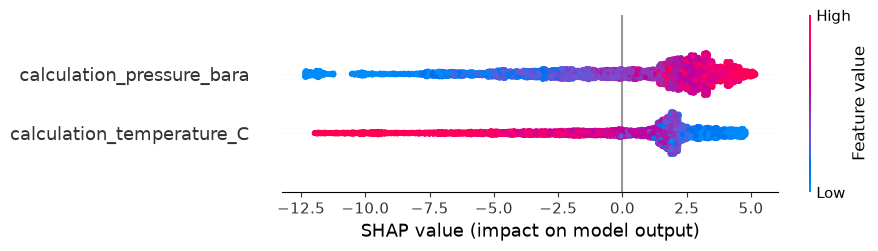

In [173]:
import shap


explainer = shap.TreeExplainer(best_clf)
shap_values = explainer(X)
shap.plots.beeswarm(shap_values, max_display=15, show=False);

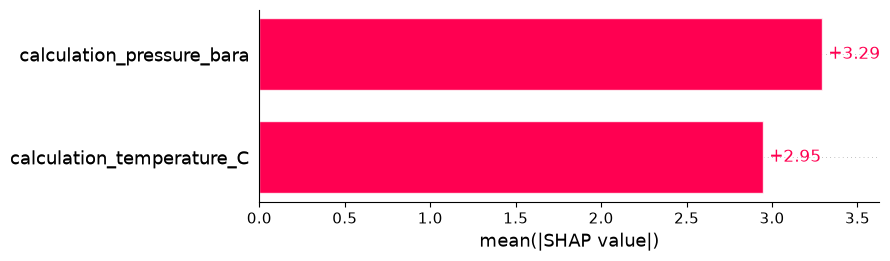

In [174]:
shap.plots.bar(shap_values, max_display=15)

## 5.3. Метрики для моделей комбинированной регрессии

### 5.3.1. Метрики для модели классификации

In [107]:
results = []

for model_name, scaler_models in combo_clf.items():
    for scaler_key, model in scaler_models.items():
        y_train_pred = model.predict(X_train_dict[scaler_key])
        y_test_pred = model.predict(X_test_dict[scaler_key])

        train_metrics = calculate_metrics_clf(y_train_cls, y_train_pred)
        test_metrics = calculate_metrics_clf(y_test_cls, y_test_pred)

        row = {
            "Модель": model_name,
            "Обработка": scaler_names[scaler_key]
        }

        for metric, value in test_metrics.items():
            row[f"{metric}_test"] = value

        for metric in train_metrics:
            row[f"Delta_{metric}"] = (
                test_metrics[metric] - train_metrics[metric]
            )

        results.append(row)

In [108]:
metrics_df = pd.DataFrame(results)
metrics_df.sort_values('F1-score_test', ascending=False)

,Модель,Обработка,Precision_test,Recall_test,F1-score_test,ROC-AUC_test,Delta_Precision,Delta_Recall,Delta_F1-score,Delta_ROC-AUC
7,CatBoostClassifier,RobustScaler,0.995224,0.999041,0.997129,0.989521,-0.002142,0.000479,-0.000835,-0.004244
4,CatBoostClassifier,Нет,0.995220,0.998082,0.996649,0.989041,-0.002863,0.000000,-0.001433,-0.005988
5,CatBoostClassifier,StandardScaler,0.994269,0.998082,0.996172,0.987041,-0.003097,-0.000240,-0.001672,-0.006603
6,CatBoostClassifier,MinMaxScaler,0.994264,0.997124,0.995692,0.986562,-0.003820,-0.001678,-0.002751,-0.008827
1,KNeighborsClassifier,StandardScaler,0.993314,0.997124,0.995215,0.984562,-0.003325,0.001918,-0.000707,-0.006020
2,KNeighborsClassifier,MinMaxScaler,0.992366,0.997124,0.994739,0.982562,-0.004752,0.001918,-0.001422,-0.009023
9,RandomForestClassifier,StandardScaler,0.993308,0.996165,0.994734,0.984082,-0.006692,-0.003835,-0.005266,-0.015918
0,KNeighborsClassifier,Нет,0.994253,0.995206,0.994729,0.985603,-0.000721,-0.001198,-0.000959,-0.002068
11,RandomForestClassifier,RobustScaler,0.992359,0.996165,0.994258,0.982082,-0.007641,-0.003835,-0.005742,-0.017918
8,RandomForestClassifier,Нет,0.992359,0.996165,0.994258,0.982082,-0.007641,-0.003835,-0.005742,-0.017918


In [169]:
best_clf = combo_clf['CatBoostClassifier']['base']
y_pred = best_clf.predict(X_test)

print(classification_report(y_test_reg_flag, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99       250
           1       1.00      1.00      1.00      1043

    accuracy                           0.99      1293
   macro avg       0.99      0.99      0.99      1293
weighted avg       0.99      0.99      0.99      1293



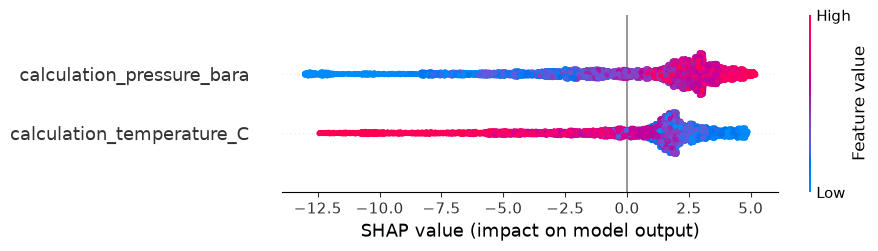

In [170]:
import shap


explainer = shap.TreeExplainer(best_clf)
shap_values = explainer(X)
shap.plots.beeswarm(shap_values, max_display=15, show=False);

### 5.3.2. Метрики для модели регрессии

In [117]:
results = []

for model_name, scaler_models in combo_reg.items():
    for scaler_key, model in scaler_models.items():
        y_train_pred = model.predict(X_train_reg_flag_dict[scaler_key])
        y_test_pred = model.predict(X_test_reg_flag_dict[scaler_key])

        train_metrics = calculate_metrics_reg(y_train_non_zero, y_train_pred)
        test_metrics = calculate_metrics_reg(y_test_non_zero, y_test_pred)

        row = {
            "Модель": model_name,
            "Обработка": scaler_names[scaler_key]
        }

        for metric, value in test_metrics.items():
            row[f"{metric}_test"] = value

        for metric in train_metrics:
            row[f"Delta_{metric}"] = (
                test_metrics[metric] - train_metrics[metric]
            )

        results.append(row)

In [118]:
metrics_df = pd.DataFrame(results)
metrics_df.sort_values('R2_test', ascending=False)

,Модель,Обработка,MAE_test,MSE_test,MAPE_test,R2_test,Delta_MAE,Delta_MSE,Delta_MAPE,Delta_R2
0,ElasticNet,Нет,0.003916,0.000024,0.215986,0.993748,-0.001914,-0.016670,-0.047733,0.832672
1,ElasticNet,StandardScaler,0.003917,0.000024,0.216165,0.993743,-0.001913,-0.016670,-0.047795,0.832667
3,ElasticNet,RobustScaler,0.003956,0.000024,0.217559,0.993645,-0.001912,-0.016670,-0.047913,0.832569
2,ElasticNet,MinMaxScaler,0.004097,0.000026,0.222507,0.993279,-0.001907,-0.016669,-0.048290,0.832205
5,CatBoostRegressor,StandardScaler,0.008272,0.000658,0.927229,0.828147,-0.000690,-0.008695,0.406289,0.298137
6,CatBoostRegressor,MinMaxScaler,0.007669,0.000810,0.941342,0.788353,-0.000418,-0.006357,0.487640,0.148502
7,CatBoostRegressor,RobustScaler,0.009098,0.000919,1.189081,0.759799,-0.000533,-0.008148,0.550017,0.215440
4,CatBoostRegressor,Нет,0.007122,0.001271,1.174845,0.667900,-0.000101,-0.004531,0.672426,-0.040530


In [171]:
best_reg = combo_reg['ElasticNet']['base']
y_pred = best_reg.predict(X_test_reg_flag)

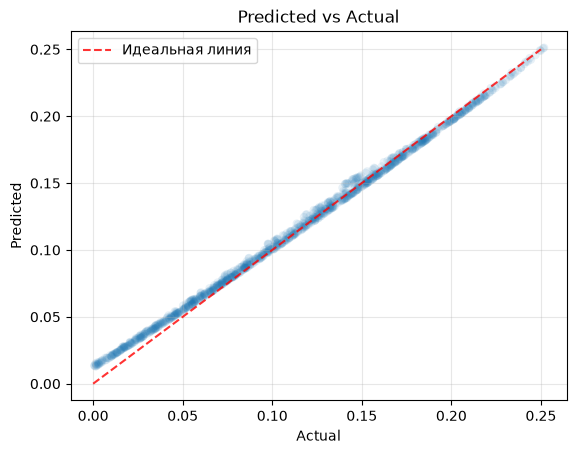

In [172]:
plt.scatter(y_test_non_zero, y_pred, alpha=0.1, edgecolors='none')
plt.plot([0, 0.25], [0, 0.25], 'r--', alpha=0.8, linewidth=1.5, label='Идеальная линия')


plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Predicted vs Actual')
plt.legend()
plt.grid(True, alpha=0.3)

### 5.3.3. Метрики для последовательности моделей

In [173]:
def combo_prediction(clf_model, reg_model, X):
    is_nonzero = clf_model.predict(X).astype(bool)
    
    y_pred = np.zeros(X.shape[0], dtype=float)
    
    if is_nonzero.any():
        reg_pred = reg_model.predict(X[is_nonzero])
        y_pred[is_nonzero] = reg_pred
    
    return y_pred

In [174]:
y_pred = combo_prediction(best_clf, best_reg, X_test)

In [175]:
calculate_metrics_reg(y_test_reg, y_pred)

{'MAE': 0.003243372634673636,
 'MSE': 2.371119898747653e-05,
 'MAPE': 452250919971.5409,
 'R2': 0.9953143878419958}

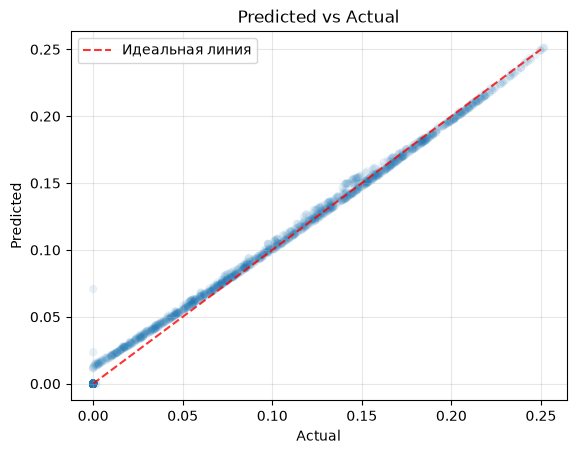

In [176]:
plt.scatter(y_test_reg, y_pred, alpha=0.1, edgecolors='none')
plt.plot([0, 0.25], [0, 0.25], 'r--', alpha=0.8, linewidth=1.5, label='Идеальная линия')


plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Predicted vs Actual')
plt.legend()
plt.grid(True, alpha=0.3)

# 6. Результат работы